# Comprehensive Global Stock Market Research
## Factor-Based Analysis Across 5 Major Markets

**Markets Covered**: China, Europe, Japan, Korea, United States

**Analysis Components**
1. Factor Performance Analysis
2. Sector Analysis
3. Cross-Country Comparison
4. Market Interpretation & Insights

---
## Setup and Data Loading

In [5]:
import configparser

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings

from openai import http_client

warnings.filterwarnings('ignore')

# Set plotting style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12

# Color palette for countries
COUNTRY_COLORS = {
    'china': '#E63946',
    'europe': '#457B9D',
    'japan': '#2A9D8F',
    'korea': '#E9C46A',
    'us': '#264653'
}

# Factor colors
FACTOR_COLORS = {
    'BM': '#E63946',
    'HML': '#F4A261',
    'SMB': '#2A9D8F',
    'MOM': '#264653',
    'OP': '#8338EC',
    'INV': '#06D6A0',
    'REV': '#118AB2'
}

# Base path
BASE_PATH = Path('.')
COUNTRIES = ['us', 'europe', 'japan', 'china', 'korea']

print("Setup complete. Loading data...")

Setup complete. Loading data...


In [6]:
# GICS Sector mapping
SECTOR_NAMES = {
    '10': 'Energy',
    '15': 'Materials',
    '20': 'Industrials',
    '25': 'Consumer Disc.',
    '30': 'Consumer Staples',
    '35': 'Health Care',
    '40': 'Financials',
    '45': 'Info Tech',
    '50': 'Comm. Services',
    '55': 'Utilities',
    '60': 'Real Estate'
}

In [7]:
# Data containers
data = {
    'total_ER': {}, # whole univers's equity expected returns
    'beta': {}, # whole universe's equity factor exposure
    'factor_hs': {}, # historical factor returns
    'factor_hs_clipped': {}, # clipped historical factor returns(recent 52 weeks, normalized to 100)
    'factor_ts': {}, # historical factor expected returns
    'factor_ts_clipped': {}, # clipped historical factor expected returns(recent 52 weeks, normalized to 100)
    'index_ts': {}, # historical index expected returns
    'index_ts_clipped': {}, # clipped historical index expected returns(recent 52 weeks, normalized to 100)
    'sector_ts': {}, # historical sector expected returns
    'sector_ts_clipped': {}, # clipped historical sector expected returns(recent 52 weeks, normalized to 100)
    'industry_ts' : {}, # historical industry expected returns
    'industry_ts_clipped': {}, # clipped historical industry expected returns(recent 52 weeks, normalized to 100)
    'factor_ER': {}, # factor expected returns for most recent month
    'index_ER': {}, # index expected returns for most recent month
    'sector_ER': {}, # sector expected returns for most recent month
    'industry_ER': {}, # industry expected returns for most recent month
    'size_ER': {}, # size quintile expected returns for most recent month
    'top_bot': {}, # top and bottom 10 stocks by expected return
}

def clip_ts(df, periods=52):
    """Clip time series to the last 'periods' entries and normalize to 100"""
    clipped = df[-periods:]
    clipped = (clipped / clipped.iloc[0]) * 100
    return clipped

# Load all data
for country in COUNTRIES:
    country_path = BASE_PATH / country

    # Load each file type
    data['total_ER'][country] = pd.read_csv(country_path / 'total_ER.csv', index_col=0, dtype={'sector':str})
    data['beta'][country] = pd.read_csv(country_path / 'beta.csv', index_col=0, dtype={'sector':str, 'industry':str})

    # historical time series of factor index
    data['factor_hs'][country] = pd.read_csv(country_path / 'factor_hs.csv', index_col=0, parse_dates=True)
    data['factor_hs_clipped'][country] = clip_ts(data['factor_hs'][country])
    # time series of factor index's expected return index
    data['factor_ts'][country] = pd.read_csv(country_path / 'factor_ts.csv', index_col=0, parse_dates=True)
    data['factor_ts_clipped'][country] = clip_ts(data['factor_ts'][country])
    # time series of country index's expected return index
    data['index_ts'][country] = pd.read_csv(country_path / 'index_ts.csv', index_col=0, parse_dates=True)
    data['index_ts_clipped'][country] = clip_ts(data['index_ts'][country])
    # time series of sector index's expected return index
    data['sector_ts'][country] = pd.read_csv(country_path / 'sector_ts.csv', index_col=0, parse_dates=True)
    data['sector_ts_clipped'][country] = clip_ts(data['sector_ts'][country])
    # time series of industry index's expected return index
    data['industry_ts'][country] = pd.read_csv(country_path / 'industry_ts.csv', index_col=0, parse_dates=True)
    data['industry_ts_clipped'][country] = clip_ts(data['industry_ts'][country])

    data['factor_ER'][country] = pd.read_csv(country_path / 'factor_ER.csv')
    data['index_ER'][country] = pd.read_csv(country_path / 'index_ER.csv')
    data['sector_ER'][country] = pd.read_csv(country_path / 'sector_ER.csv', dtype={'sector':str})
    data['industry_ER'][country] = pd.read_csv(country_path / 'industry_ER.csv', dtype={'industry':str})

    data['size_ER'][country] = pd.read_csv(country_path / 'size_ER.csv')
    data['top_bot'][country] = pd.read_csv(country_path / 'ERtop+bot10.csv', dtype={'sector':str})

print("Data loaded successfully!")
print(f"\nCountries: {COUNTRIES}")
print(f"\nStock counts by market:")
for country in COUNTRIES:
    print(f"  {country.upper()}: {len(data['total_ER'][country]):,} stocks")

Data loaded successfully!

Countries: ['us', 'europe', 'japan', 'china', 'korea']

Stock counts by market:
  US: 2,939 stocks
  EUROPE: 599 stocks
  JAPAN: 496 stocks
  CHINA: 575 stocks
  KOREA: 296 stocks


In [8]:
data['factor_hs_clipped']['korea'].to_clipboard()

In [9]:
# NORMALIZATION FUNCTIONS FOR CROSS-COUNTRY COMPARISON
# Since factor models have different scales across countries, we need to
# normalize values before making cross-country comparisons.

def zscore_normalize(series):
    """Convert to z-scores (mean=0, std=1)"""
    return (series - series.mean()) / series.std()

def normalize(er, ts, er_ind:str, er_col:str, ts_col:str=None):
    """Normalize ER values using z-score based on time series data"""
    er_with_index = er.set_index(er_ind, inplace=False)
    er_val = er_with_index[er_col] / 100
    if ts_col is not None:
        ts_er = ts.filter(like=ts_col, axis=1)
        ts_er.columns = ts_er.columns.str.replace(ts_col, '')
    else:
        ts_er = ts
    ts_mean = ts_er.mean()
    ts_std = ts_er.std()

    data = pd.concat([er_val, ts_mean, ts_std], axis=1)
    data.columns = ['ER', 'Mean', 'Std']
    zscore = (data['ER'] - data['Mean']) / data['Std']
    zscore.name = 'ER_zscore'
    result = pd.concat([er_with_index, zscore], axis=1).dropna()

    return result

# Create normalized versions of key data
print("\n" + "="*70)
print("CREATING NORMALIZED DATA FOR CROSS-COUNTRY COMPARISON")
print("="*70)

# Normalize ER data for each country
for country in COUNTRIES:
    # Normalize equity ERs
    total_er = data['total_ER'][country].copy()
    if 'ER' in total_er.columns:
        total_er['ER_zscore'] = zscore_normalize(total_er['ER'])
    data['total_ER'][country] = total_er

    # Normalize index ERs
    er = data['index_ER'][country].copy()
    ts = data['index_ts'][country].copy()

    data['index_ER'][country] = normalize(er, ts, 'index', 'wER', '_ER')

    # Normalize sector ERs
    er = data['sector_ER'][country].copy()
    ts = data['sector_ts'][country].copy()

    data['sector_ER'][country] = normalize(er, ts, 'sector', 'wER', '_ER')

    # Normalize industry ERs
    er = data['industry_ER'][country].copy()
    ts = data['industry_ts'][country].copy()

    data['industry_ER'][country] = normalize(er, ts, 'industry', 'wER', '_ER')

    # Normalize factor returns (relative strength within country)
    er = data['factor_ER'][country].copy()
    ts = data['factor_ts'][country].copy()
    data['factor_ER'][country] = normalize(er, ts, 'factor', 'ER', '_ER')

print("Normalization methods applied:")
print("  • Z-Score: Standardized (mean=0, std=1) - good for relative comparisons")
print("  • Note: Use normalized values for cross-country comparisons")


CREATING NORMALIZED DATA FOR CROSS-COUNTRY COMPARISON
Normalization methods applied:
  • Z-Score: Standardized (mean=0, std=1) - good for relative comparisons
  • Note: Use normalized values for cross-country comparisons


In [10]:
# ============================================================
# LLM Commentary Helper  (web search + persistent conversation)
# Requires: pip install openai
# Set environment variable: OPENAI_API_KEY=your-key
# ============================================================
import os
import datetime
from IPython.display import display, Markdown

OPENAI_MODEL = "gpt-5-mini"  # change to "gpt-4o" for higher quality

_conversation_history = []

_SYSTEM_MESSAGE = {
    "role": "system",
    "content": (
        "당신은 글로벌 대형 기관투자자를 대상으로 미국, 유럽, 일본, 중국, 한국 시장의 "
        "멀티팩터 포트폴리오 전략을 수립하는 '뉴스 통합형 시니어 퀀트 전략가(News-Integrated Chief Quant Strategist)'입니다.\n\n"
        "【핵심 분석 원칙】\n"
        "1. 최신 뉴스 우선: 반드시 현재 날짜 기준 최근 2~4주 이내의 실제 시장 뉴스, 거시경제 이벤트, 정책 발표, 기업 공시를 먼저 검색하고 이를 분석의 중심으로 삼으십시오.\n"
        "2. 팩터 데이터는 보조 근거: 제공된 Z-스코어, 방향성(상승/하락) 등 팩터 데이터는 뉴스 해석을 뒷받침하는 정량적 확인 도구로만 활용하십시오. 수치를 직접 나열하는 것을 금지합니다.\n"
        "3. 이벤트-드리븐 내러티브: 모든 분석은 '어떤 사건/정책/테마가 이 팩터·섹터·종목을 움직이는가'라는 질문에 답하는 형식으로 서술하십시오.\n"
        "4. Bottom-line Up Front: 가장 중요한 뉴스 기반 투자 시그널부터 시작하고, 수치는 괄호 안에 간략히 표기하십시오.\n"
        "5. 격식체 한국어: 투자위원회(IC) 제출용 보고서에 부합하는 명사형 어미(~함, ~임, ~판단, ~권고)를 사용하십시오.\n"
        "6. 최신성 보장: 검색 시 반드시 현재 연도·월을 포함한 쿼리를 사용하여 최신 뉴스만 인용하십시오."
    )
}

def reset_conversation():
    global _conversation_history
    _conversation_history = []
    print("대화 기록이 초기화되었습니다.")

def llm_explain(data_str: str, prompt: str, use_search: bool = True) -> str:
    global _conversation_history
    try:
        from openai import OpenAI
        import httpx
        key = os.getenv('OPENAI_API_KEY', '')
        if not key:
            return "_LLM 해설을 사용할 수 없습니다 — `OPENAI_API_KEY` 환경 변수를 설정하세요._"

        client = OpenAI(api_key=key, http_client=httpx.Client(verify=False))
        today = datetime.date.today().isoformat()
        date_preamble = f"[오늘 날짜: {today}. 최근 2~4주 이내의 최신 뉴스를 검색하여 분석에 활용하십시오.]\n\n"
        user_message = {
            "role": "user",
            "content": date_preamble + prompt + "\n\nData:\n" + data_str
        }
        messages = [_SYSTEM_MESSAGE] + _conversation_history + [user_message]
        kwargs = dict(model=OPENAI_MODEL, input=messages)
        if use_search:
            kwargs["tools"] = [{"type": "web_search_preview"}]
        response = client.responses.create(**kwargs)
        reply = response.output_text
        _conversation_history.append(user_message)
        _conversation_history.append({"role": "assistant", "content": reply})
        return reply
    except ImportError:
        return "_`openai` 패키지가 설치되지 않았습니다 — `pip install openai`를 실행하세요._"
    except Exception as e:
        return f"_LLM 오류: {e}_"

def show_explanation(data_str: str, prompt: str, title: str = "분석 해설", use_search: bool = True):
    text = llm_explain(data_str, prompt, use_search=use_search)
    display(Markdown(f"---\n### 💬 {title}\n\n{text}\n\n---"))

reset_conversation()
print(f"LLM 헬퍼 로드 완료. 모델: {OPENAI_MODEL}")
print("대화 메모리: 활성화 (초기화하려면 reset_conversation() 호출)")
print("웹 검색: 활성화 (최신 뉴스 기반 분석)")
print("API 키:", "✓ 설정됨" if os.getenv('OPENAI_API_KEY') else "✗ 미설정 (OPENAI_API_KEY 환경 변수를 설정하세요)")

대화 기록이 초기화되었습니다.
LLM 헬퍼 로드 완료. 모델: gpt-5-mini
대화 메모리: 활성화 (초기화하려면 reset_conversation() 호출)
웹 검색: 활성화 (최신 뉴스 기반 분석)
API 키: ✓ 설정됨


---
## Historical Analysis

### Factor Time Series Performance

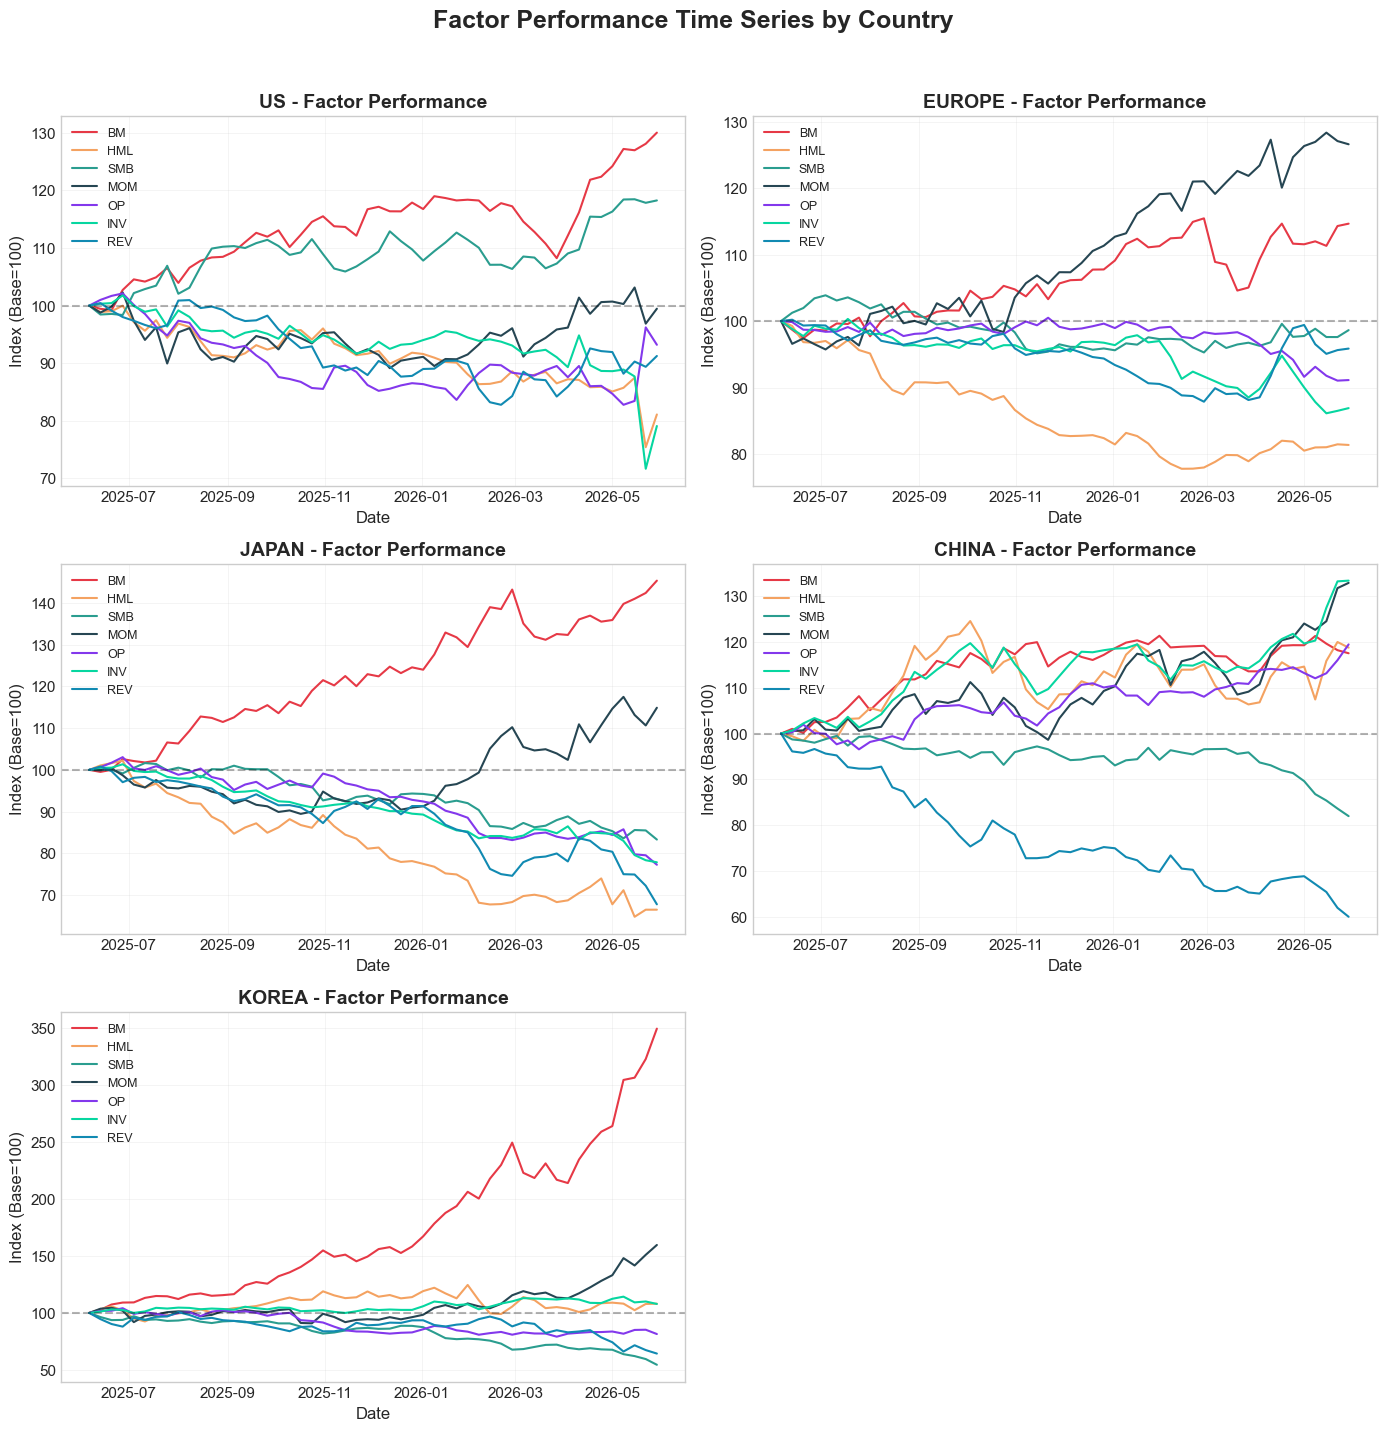

In [11]:
# Plot factor time series for each country
fig, axes = plt.subplots(3, 2, figsize=(14, 14))
axes = axes.flatten()

for idx, country in enumerate(COUNTRIES):
    ax = axes[idx]
    factor_ts = data['factor_hs_clipped'][country]

    for col in factor_ts.columns:
        if col in FACTOR_COLORS:
            ax.plot(factor_ts.index, factor_ts[col], label=col,
                   color=FACTOR_COLORS.get(col, 'gray'), linewidth=1.5)

    ax.axhline(y=100, color='black', linestyle='--', alpha=0.3)
    ax.set_title(f'{country.upper()} - Factor Performance', fontsize=14, fontweight='bold')
    ax.set_xlabel('Date')
    ax.set_ylabel('Index (Base=100)')
    ax.legend(loc='upper left', fontsize=9)
    ax.grid(True, alpha=0.3)

# Hide the 6th subplot
axes[5].axis('off')

plt.suptitle('Factor Performance Time Series by Country', fontsize=18, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [12]:
# Calculate factor statistics
def calculate_factor_stats(factor_ts):
    """Calculate comprehensive factor statistics"""
    returns = factor_ts.pct_change().dropna()

    stats = pd.DataFrame({
        'Total Return (%)': ((factor_ts.iloc[-1] / factor_ts.iloc[0]) - 1) * 100,
        'Ann. Return (%)': returns.mean() * 52 * 100,
        'Ann. Vol (%)': returns.std() * np.sqrt(52) * 100,
        'Sharpe Ratio': (returns.mean() * 52) / (returns.std() * np.sqrt(52)),
        'Max Drawdown (%)': ((factor_ts / factor_ts.cummax()) - 1).min() * 100,
        'Skewness': returns.skew(),
        'Kurtosis': returns.kurtosis()
    })
    return stats.round(3)

# Display factor stats for each country
for country in COUNTRIES:
    print(f"\n{'='*70}")
    print(f"{country.upper()} - FACTOR STATISTICS")
    print("="*70)
    stats = calculate_factor_stats(data['factor_hs_clipped'][country])
    display(stats.style.format('{:.1f}').background_gradient(cmap='RdYlGn', subset=['Sharpe Ratio'], axis=0))


US - FACTOR STATISTICS


,Total Return (%),Ann. Return (%),Ann. Vol (%),Sharpe Ratio,Max Drawdown (%),Skewness,Kurtosis
BM,30.0,27.6,12.5,2.2,-9.0,0.3,-0.1
HML,-18.9,-19.4,19.3,-1.0,-24.6,-2.0,13.0
SMB,18.3,18.0,13.1,1.4,-5.8,0.2,0.7
MOM,-0.5,1.2,18.9,0.1,-12.8,-0.4,0.5
OP,-6.8,-5.3,19.9,-0.3,-18.9,3.6,19.2
INV,-20.9,-20.8,24.4,-0.9,-29.6,-2.3,17.2
REV,-8.8,-8.2,14.9,-0.6,-18.0,0.4,0.8



EUROPE - FACTOR STATISTICS


,Total Return (%),Ann. Return (%),Ann. Vol (%),Sharpe Ratio,Max Drawdown (%),Skewness,Kurtosis
BM,14.6,14.8,12.8,1.2,-9.4,-0.8,1.7
HML,-18.6,-20.6,8.8,-2.3,-22.2,-0.2,0.3
SMB,-1.4,-1.1,7.4,-0.2,-8.4,0.1,0.5
MOM,26.6,25.2,15.2,1.7,-5.7,-0.4,1.0
OP,-8.9,-9.3,6.6,-1.4,-9.4,-0.4,-0.0
INV,-13.1,-13.9,9.4,-1.5,-14.1,-0.0,0.4
REV,-4.1,-3.9,9.6,-0.4,-12.3,1.3,3.3



JAPAN - FACTOR STATISTICS


,Total Return (%),Ann. Return (%),Ann. Vol (%),Sharpe Ratio,Max Drawdown (%),Skewness,Kurtosis
BM,45.4,39.3,14.3,2.7,-8.4,-0.4,0.7
HML,-33.5,-39.5,19.7,-2.0,-36.6,-0.9,1.8
SMB,-16.7,-18.1,10.2,-1.8,-18.0,-0.3,0.3
MOM,14.9,15.7,17.8,0.9,-10.9,0.9,1.4
OP,-22.8,-25.6,11.8,-2.2,-25.0,-1.2,4.3
INV,-22.2,-25.1,8.5,-3.0,-23.2,-0.5,1.9
REV,-32.2,-38.0,17.7,-2.1,-32.8,0.2,2.0



CHINA - FACTOR STATISTICS


,Total Return (%),Ann. Return (%),Ann. Vol (%),Sharpe Ratio,Max Drawdown (%),Skewness,Kurtosis
BM,17.5,17.1,11.9,1.4,-6.4,-0.3,0.1
HML,18.7,19.9,22.0,0.9,-15.4,-0.1,-0.0
SMB,-18.0,-19.7,10.0,-2.0,-18.0,0.2,-0.1
MOM,32.8,30.9,19.5,1.6,-11.3,-0.3,-0.1
OP,19.4,18.7,11.1,1.7,-5.3,0.3,-0.1
INV,33.3,30.5,14.9,2.0,-9.4,0.1,-0.2
REV,-39.9,-50.1,18.0,-2.8,-39.9,0.3,0.4



KOREA - FACTOR STATISTICS


,Total Return (%),Ann. Return (%),Ann. Vol (%),Sharpe Ratio,Max Drawdown (%),Skewness,Kurtosis
BM,249.3,134.0,31.8,4.2,-14.2,-0.2,1.4
HML,8.1,12.5,30.4,0.4,-20.5,-0.3,0.7
SMB,-45.5,-59.6,19.2,-3.1,-45.5,-0.6,0.2
MOM,59.6,52.4,30.3,1.7,-13.0,-0.5,1.5
OP,-18.5,-19.3,17.5,-1.1,-24.0,-0.2,-0.4
INV,7.9,8.6,13.2,0.6,-6.2,-0.2,0.0
REV,-35.6,-40.5,29.4,-1.4,-36.1,0.0,0.3


### Factor Correlation Analysis

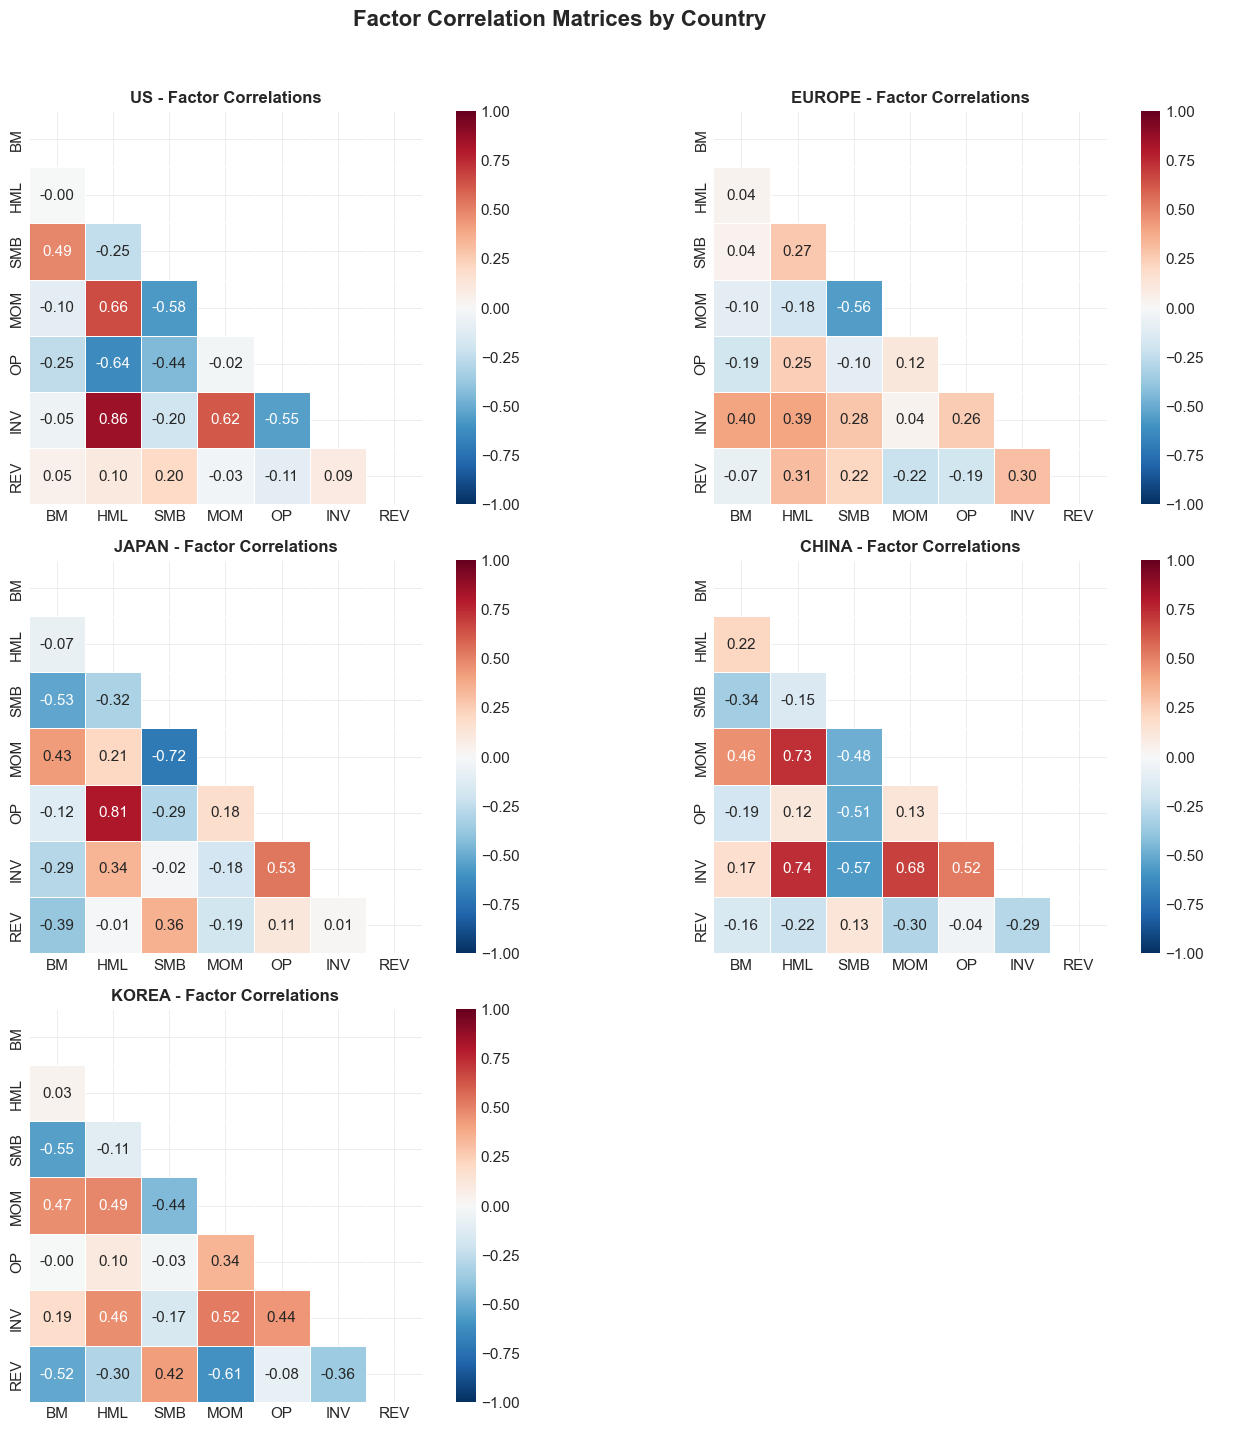

In [13]:
# Factor correlation matrices
fig, axes = plt.subplots(3, 2, figsize=(14, 14))
axes = axes.flatten()

for idx, country in enumerate(COUNTRIES):
    ax = axes[idx]
    factor_returns = data['factor_hs_clipped'][country].pct_change().dropna()
    corr = factor_returns.corr()

    mask = np.triu(np.ones_like(corr, dtype=bool))
    sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
                center=0, ax=ax, vmin=-1, vmax=1,
                square=True, linewidths=0.5)
    ax.set_title(f'{country.upper()} - Factor Correlations', fontsize=12, fontweight='bold')

axes[5].axis('off')
plt.suptitle('Factor Correlation Matrices by Country', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [14]:
# === LLM Commentary: Historical Analysis (News-Driven) ===
_hist_txt = f"HISTORICAL ANALYSIS — Factor Direction Summary (week ending approx. {datetime.date.today().isoformat()})\n\n"

for _c in COUNTRIES:
    _hs = data['factor_hs_clipped'][_c]
    _ret4  = (_hs.iloc[-1] / _hs.iloc[-5]  - 1) * 100 if len(_hs) >= 5 else pd.Series(dtype=float)
    _prior4 = (_hs.iloc[-5] / _hs.iloc[-9] - 1) * 100 if len(_hs) >= 9 else pd.Series(dtype=float)
    _accel = (_ret4 - _prior4).dropna().sort_values(ascending=False)
    _top3 = list(_accel.head(3).index)
    _bot3 = list(_accel.tail(3).index)
    _hist_txt += f"{_c.upper()}: 가속 팩터={', '.join(_top3)} | 감속 팩터={', '.join(_bot3)}\n"

_hist_prompt = (
    "당신은 글로벌 퀀트 전략가입니다. 제공된 국가별 팩터 가속/감속 방향 요약을 바탕으로 각 시장의 최신 거시경제 뉴스를 검색하십시오.\n\n"
    "검색 지시: 각 국가별로 '[국가명] stock market factor style rotation news [현재연월]', '[국가명] 금리 통화정책 최신 뉴스' 쿼리로 최신 이벤트를 검색하십시오.\n\n"
    "출력 구조:\n"
    "1. 핵심 뉴스 드라이버 (국가별): 각 시장에서 팩터 흐름을 주도하는 실제 이벤트/정책/테마를 뉴스 기반으로 서술. 팩터 방향은 괄호 안에 간략 표기.\n"
    "2. 글로벌 공통 테마: 여러 시장에서 동시에 관찰되는 스타일 로테이션의 배경 이벤트.\n"
    "분량: A4 0.5페이지 이내. 수치 나열 금지. 뉴스 내러티브 우선."
)

show_explanation(_hist_txt, _hist_prompt, title="1.3 Historical Analysis: 뉴스 기반 팩터 동인 분석")

---
### 💬 1.3 Historical Analysis: 뉴스 기반 팩터 동인 분석

요약(결론 먼저): 6월 중순 중앙은행·정책 이벤트가 스타일 로테이션을 촉발하고 있어, 향후 2–4주간은 금리·유동성 신호에 민감한 가치·수익성·소형(및 설비투자 노출) 팩터가 상대적 우위를 가질 가능성이 큼(아래 국가별 근거).  

1) 핵심 뉴스 드라이버(국가별)
- 미국 — Fed의 6/17 회의에서 정책금리 동결·완화 기대 문구 제거 및 일부 위원들의 추가 인상 시사로 통신·AI 중심 모멘텀에서 가치·수익성·소형으로 자금 이동이 가속됨 (가속: OP, HML, SMB; 감속: BM, REV, INV). ([investing.com](https://www.investing.com/news/economy-news/fed-begins-warsh-era-by-keeping-rates-on-hold-sees-hike-later-this-year-4748033?utm_source=openai))  
- 유로권(유럽) — ECB가 6/11 기준금리 인상으로 에너지 충격에 대응하는 긴축 기조가 확인되면서 모멘텀성 고성장(대형 성장주)보다 밸류·수익성 노출이 선호됨 (가속: OP, BM, HML; 감속: MOM, INV, REV). ([ecb.europa.eu](https://www.ecb.europa.eu/press/pr/date/2026/html/ecb.mp260611~4d41bd5e83.en.html))  
- 일본 — BOJ의 6월 금리 추가 인상(정책금리 1%대 진입)에 따른 통화정상화가 진행되어, 이자율 민감·밸류·소형 요소로 자금이 재배분되는 흐름 관찰됨 (가속: BM, SMB, HML; 감속: OP, MOM, REV). ([investing.com](https://www.investing.com/news/economy-news/boj-raises-interest-rates-to-31year-high-in-widely-expected-move-4743777?utm_source=openai))  
- 중국 — 인덱스(6월 중순 리밸런싱)·PBoC의 단기금리 조정·유동성 운영 강화 발표가 결합되며 설비투자·영업실적·가치 노출이 부각되고 모멘텀(단기 추세)은 약화됨 (가속: INV, OP, HML; 감속: MOM, BM, REV). ([investing.com](https://www.investing.com/news/economy-news/china-central-banks-deepening-control-on-shortterm-rates-sparks-debate-over-policy-focus-4746650?utm_source=openai))  
- 한국 — 반도체 이익실현 국면과 동시에 BOK의 인상 신호(기준금리 동결 후 향후 인상 시사)가 맞물려 모멘텀·밸류·반전 팩터가 활발히 움직이는 가운데, 수급·변동성 관리 이슈로 운영상 리스크가 증대됨 (가속: BM, MOM, REV; 감속: OP, HML, SMB). ([en.yna.co.kr](https://en.yna.co.kr/view/AEN20260611010500320?utm_source=openai))

2) 글로벌 공통 테마
- 중동발 에너지·인플레이션 충격으로 선진국 중앙은행들의 정책 경로 재평가가 진행되어(긴축·데이터의존적 운영), 성장·모멘텀 기반의 초대형 기술주 우위 구도에서 가치·수익성·소형(실적·대체수급에 민감)으로 자금이 분산되는 '정책·수급 주도 로테이션'이 관찰됨. (상기 중앙은행 메시지들이 핵심 드라이버임). ([investing.com](https://www.investing.com/news/economy-news/fed-begins-warsh-era-by-keeping-rates-on-hold-sees-hike-later-this-year-4748033?utm_source=openai))

3) 단기 투자 시그널(향후 2–4주, 우선순위)
- 시그널 A — 미국: 가치(BM)·영업수익성(OP)·소형(SMB)으로의 구조적 리밸런싱을 단기전술로 활용할 것(연관 근거: Fed의 불확실성·긴축 가능성 및 기술 모멘텀 약화). ([investing.com](https://www.investing.com/news/economy-news/fed-begins-warsh-era-by-keeping-rates-on-hold-sees-hike-later-this-year-4748033?utm_source=openai))  
- 시그널 B — 일본: 밸류·소형(BM·SMB)과 수출·금리 민감 업종(금융·중공업)에 초점을 맞출 것(근거: BOJ의 추가 정상화와 엔·수출 민감도 재평가). ([investing.com](https://www.investing.com/news/economy-news/boj-raises-interest-rates-to-31year-high-in-widely-expected-move-4743777?utm_source=openai))  
- 시그널 C — 중국: 설비투자·영업실적·인덱스 리밸런싱 수혜(건설·자본재·IT 인프라 장비 등 INV·OP) 비중 확대를 고려할 것(근거: PBoC의 단기금리 관리 강화·6월 인덱스 리밸런싱에 따른 기계적 자금흐름). ([investing.com](https://www.investing.com/news/economy-news/china-central-banks-deepening-control-on-shortterm-rates-sparks-debate-over-policy-focus-4746650?utm_source=openai))

짧은 코멘트(리스크·운영): 중앙은행 의사표현(회의별·단기금리 관리)과 인덱스 리밸런싱 일정이 단기 공연·역풍을 만들 수 있으므로 포지셔닝은 리밸런싱·유동성 이벤트 전후로 리스크 관리(포지션 크기·실행 슬리피지) 엄격 적용할 것임.

참고(주요 출처): Reuters/Investing(미국 Fed 관련), ECB 공식 보도자료(6/11), Reuters/AP(BOJ 6/16), Reuters·중국정부·금융사 리포트(PBoC·리밸런싱), Yonhap/국내 언론(BOK 신호). ([investing.com](https://www.investing.com/news/economy-news/fed-begins-warsh-era-by-keeping-rates-on-hold-sees-hike-later-this-year-4748033?utm_source=openai))

원하시면 각 시그널별 구체적 종목·섹터 리스트(거래수단별 진입/손절 레벨 포함)로 즉시 확장 제시함.

---

---
## Stock Market(Country) Analysis

### Market Expected Returns

MARKET-LEVEL ANALYSIS

⚠️  IMPORTANT: Market ER values are NOT directly comparable across countries
    because factor models have different scales/calibrations.

[1] MARKET ER - (z-score scales)
----------------------------------------------------------------------


,Weighted Mean ER (%)
US,-0.06
EUROPE,-0.47
JAPAN,0.19
CHINA,-1.23
KOREA,1.30



[2] CROSS-COUNTRY COMPARABLE METRICS
----------------------------------------------------------------------


,Market ER Percentile,Market ER Z-Score,% Stocks Positive ER,ER Dispersion (Q80-Q20),ER Sharpe (mean/std)
Country,,,,,
US,41.1,-0.06,55.1%,3.17,0.02
EUROPE,25.8,-0.47,43.1%,1.90,-0.02
JAPAN,54.2,0.19,92.9%,1.53,0.12
CHINA,16.7,-1.23,36.9%,1.75,-0.04
KOREA,91.6,1.30,94.3%,2.92,0.14



Interpretation Guide:
  • Market ER Percentile: Higher = More strong signal for the market relative to historical periods
  • % Stocks Positive ER: Higher = More bullish signal for the market
  • ER Sharpe: Higher = More consistent positive signal across stocks


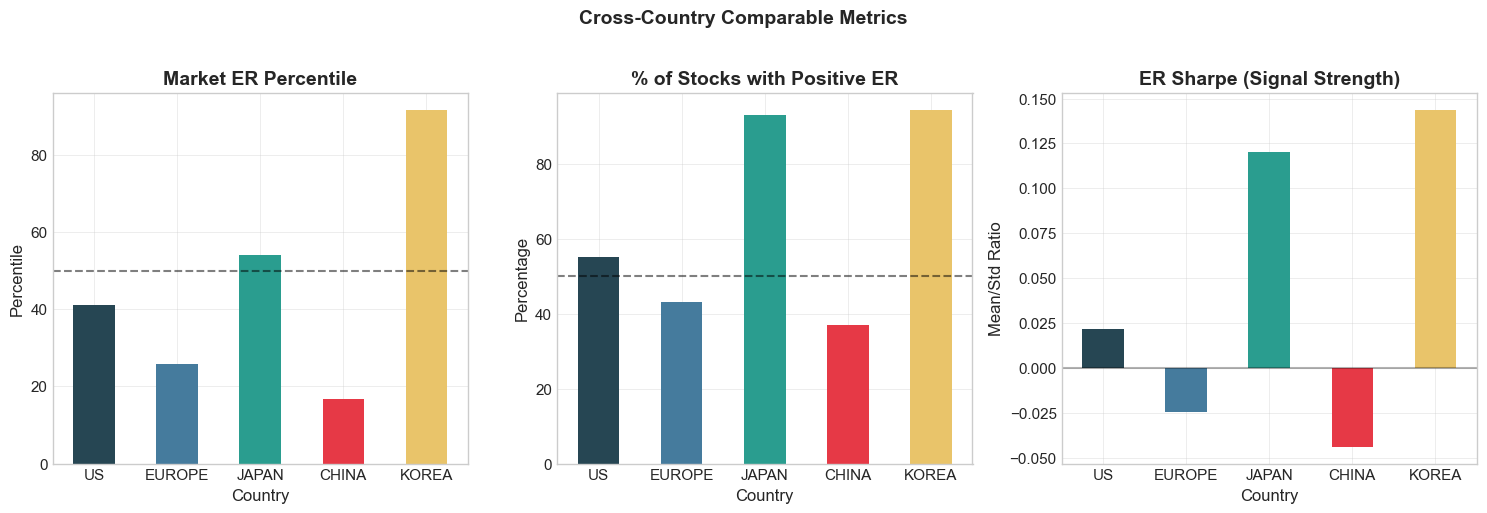

In [15]:
# Market-level expected returns comparison - WITH NORMALIZATION CONTEXT
print("="*70)
print("MARKET-LEVEL ANALYSIS")
print("="*70)
print("\n⚠️  IMPORTANT: Market ER values are NOT directly comparable across countries")
print("    because factor models have different scales/calibrations.\n")

# Raw market ERs
market_er = {}
for country in COUNTRIES:
    wmean = data['index_ER'][country]['ER_zscore'].iloc[0]
    market_er[country.upper()] = wmean

market_er_df = pd.DataFrame([market_er], index=['Weighted Mean ER (%)']).T

print("[1] MARKET ER - (z-score scales)")
print("-"*70)
display(market_er_df.style.format('{:.2f}'))

# Calculate comparable metrics using within-country distribution
print("\n[2] CROSS-COUNTRY COMPARABLE METRICS")
print("-"*70)

comparable_metrics = []
for country in COUNTRIES:
    total_stock_er = data['total_ER'][country]
    index_total_history_er = data['index_ts'][country]['index_ER']
    index_er = data['index_ER'][country]['wER'].iloc[0]

    # What percentile is the market ER within its own distribution?
    market_percentile = (index_er/100 > index_total_history_er).mean() * 100

    # Z-score of market ER within country
    market_zscore = data['index_ER'][country]['ER_zscore'].iloc[0]

    # Stock-wise
    er_values = total_stock_er['ER'].dropna()
    sh_values = total_stock_er['Sharpe'].dropna()

    # Percentage of stocks with positive ER
    pct_positive = (er_values > 0).mean() * 100

    # Spread between top and bottom quintile
    er_spread = er_values.quantile(0.8) - er_values.quantile(0.2)

    # Sharpe-like metric: mean ER / std ER
    er_sharpe = sh_values.mean()

    comparable_metrics.append({
        'Country': country.upper(),
        'Market ER Percentile': market_percentile,
        'Market ER Z-Score': market_zscore,
        '% Stocks Positive ER': pct_positive,
        'ER Dispersion (Q80-Q20)': er_spread,
        'ER Sharpe (mean/std)': er_sharpe
    })

comparable_df = pd.DataFrame(comparable_metrics).set_index('Country')
display(comparable_df.style.format({
    'Market ER Percentile': '{:.1f}',
    'Market ER Z-Score': '{:.2f}',
    '% Stocks Positive ER': '{:.1f}%',
    'ER Dispersion (Q80-Q20)': '{:.2f}',
    'ER Sharpe (mean/std)': '{:.2f}'
}).background_gradient(cmap='RdYlGn', axis=0))

print("\nInterpretation Guide:")
print("  • Market ER Percentile: Higher = More strong signal for the market relative to historical periods")
print("  • % Stocks Positive ER: Higher = More bullish signal for the market")
print("  • ER Sharpe: Higher = More consistent positive signal across stocks")

# Bar chart of comparable metrics
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Plot 1: Market Percentile
ax = axes[0]
colors = [COUNTRY_COLORS[c.lower()] for c in comparable_df.index]
comparable_df['Market ER Percentile'].plot(kind='bar', ax=ax, color=colors)
ax.set_title('Market ER Percentile', fontweight='bold')
ax.set_ylabel('Percentile')
ax.axhline(y=50, color='black', linestyle='--', alpha=0.5)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)

# Plot 2: % Positive ER
ax = axes[1]
comparable_df['% Stocks Positive ER'].plot(kind='bar', ax=ax, color=colors)
ax.set_title('% of Stocks with Positive ER', fontweight='bold')
ax.set_ylabel('Percentage')
ax.axhline(y=50, color='black', linestyle='--', alpha=0.5)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)

# Plot 3: ER Sharpe
ax = axes[2]
comparable_df['ER Sharpe (mean/std)'].plot(kind='bar', ax=ax, color=colors)
ax.set_title('ER Sharpe (Signal Strength)', fontweight='bold')
ax.set_ylabel('Mean/Std Ratio')
ax.axhline(y=0, color='black', linestyle='-', alpha=0.3)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)

plt.suptitle('Cross-Country Comparable Metrics', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [16]:
# === LLM Commentary: Stock Market Analysis (News-Driven) ===
_market_txt = f"STOCK MARKET DIRECTION SUMMARY (as of {datetime.date.today().isoformat()})\n\n"

for _c in COUNTRIES:
    _zscore = data['index_ER'][_c]['ER_zscore'].iloc[0]
    _idx_ts = data['index_ts'][_c]['index_ER']
    _cur  = float(_idx_ts.iloc[-1])
    _z4w  = float(_idx_ts.iloc[-5]) if len(_idx_ts) >= 5 else _cur
    _trend = "상승" if _cur > _z4w else "하락"
    _signal = "강세" if _zscore > 0.5 else ("약세" if _zscore < -0.5 else "중립")
    _pct_pos = (data['total_ER'][_c]['ER'].dropna() > 0).mean() * 100
    _market_txt += f"{_c.upper()}: 시그널={_signal} | ER추세={_trend} | 양(+)ER비율={_pct_pos:.0f}%\n"

_market_prompt = (
    "당신은 글로벌 자산배분 전략가입니다. 제공된 5개 시장의 방향성 요약을 바탕으로 각 국가의 최신 시장 뉴스를 검색하십시오.\n\n"
    "검색 지시: 각 국가별로 '[국가명] stock market outlook [현재연월]', '[국가명] 금리 중앙은행 최신 결정', '[국가명] 기업실적 시즌 뉴스' 쿼리로 검색하십시오.\n\n"
    "출력 구조:\n"
    "1. 국가별 시장 뉴스 브리핑 (표): 국가 | 핵심 이벤트/뉴스 | ER 방향 | 배분의견(OW/N/UW)\n"
    "2. 강세/약세 배경 뉴스: 가장 강한 시장과 가장 약한 시장 각각의 뉴스 기반 설명.\n"
    "3. 글로벌 리스크 이벤트: 전 세계 시장에 공통 영향을 미치는 리스크 요인 (뉴스 기반).\n\n"
    "분량: A4 0.5페이지. 수치 나열 금지. 뉴스 이벤트 중심 서술."
)

show_explanation(_market_txt, _market_prompt, title="1.4 Stock Market Analysis: 뉴스 기반 시장 동향")

---
### 💬 1.4 Stock Market Analysis: 뉴스 기반 시장 동향

요약(결론 먼저): 최근 중앙은행·정책 이벤트와 기업실적 흐름이 시장별로 다른 신호를 주고 있어 단기 배분은 ‘한국 OW, 중국 UW, 나머지 국가는 중립적 포지셔닝’이 합리적 판단임(아래 표·근거).  

1) 국가별 시장 뉴스 브리핑 (표)  
국가 | 핵심 이벤트/뉴스(근거) | ER 방향(입력) | 배분의견  
미국 | Fed의 6월 회의에서 금리 동결과 함께 불확실성·향후 추가인상 가능성 시사로 정책 리스크가 남아 있으며 기업실적 모멘텀 약화 신호 병행(관련 보도). ([investing.com](https://www.investing.com/news/economy-news/fed-begins-warsh-era-by-keeping-rates-on-hold-sees-hike-later-this-year-4748033?utm_source=openai)) | 하락 | N(중립)  
유럽 | ECB의 6월 금리인상(긴축 신호)에도 일부 국가·기업 실적이 개선되며 경기·실적의 불균형 회복 징후 관찰(ECB 보도·자산운용사 리포트). ([ecb.europa.eu](https://www.ecb.europa.eu/press/pr/date/2026/html/ecb.mp260611~4d41bd5e83.en.html?utm_source=openai)) | 상승 | N(중립)  
일본 | BOJ의 정책 정상화(6월 금리 인상)가 진행되어 통화·수출·밸류에이션 재평가 촉발, 실적 비율은 높으나 금리·환율 민감도 증대(현지 보도). ([centralbanking.com](https://www.centralbanking.com/central-banks/monetary-policy/monetary-policy-decisions/7976166/boj-tightens-to-1-and-plans-end-to-jgb-purchase-reductions?utm_source=openai)) | 하락 | N(중립)  
중국 | PBoC의 단기금리·유동성 조정과 정책지원 발표에도 내수·부동산 둔화로 경기 불확실성 지속, 실적 상승 비율과 시장 지표 혼재(중국 정책 발표). ([english.www.gov.cn](https://english.www.gov.cn/news/202606/17/content_WS6a324210c6d00ca5f9a0ba94.html?utm_source=openai)) | 상승 | UW(비중축소)  
한국 | 반도체·AI 중심의 실적 개선 신호와 가계 레버리지 확대(개인·마진 매수) 병행, 시장 과열(레버리지·유동성 리스크) 관찰(현지·국제 보도). ([axios.com](https://www.axios.com/2026/05/28/south-korea-ai-chips-stocks?utm_source=openai)) | 상승 | OW(비중확대)  

2) 강세/약세 배경 뉴스  
- 가장 강한 시장(한국) 배경: 반도체·AI 업종 중심의 강한 수익성 기대와 개인투자자 레버리지 유입으로 KOSPI가 상대적 강세를 보임. 다만 과열·마진대출·수급 집중은 단기 조정 리스크로 작용 가능함. ([axios.com](https://www.axios.com/2026/05/28/south-korea-ai-chips-stocks?utm_source=openai))  
- 가장 약한 시장(중국) 배경: 중앙은행·정책 당국의 유동성·지원책에도 불구하고 내수 부진과 부동산 부진이 실물 성장·신뢰 회복을 제약하여 실적 대비 시장 불확실성이 상존함. ([bbvaresearch.com](https://www.bbvaresearch.com/en/publicaciones/china-economic-outlook-june-2026/?utm_source=openai))

3) 글로벌 리스크 이벤트(뉴스 기반)  
- 중동발 에너지 공급 충격·인플레이션 재가열이 주요 선진국 중앙은행의 정책 재평가(긴축 지속 또는 불확실성 확대)를 촉발하여 전반적 스타일 로테이션과 변동성 확대를 유발함(에너지·금리·수급 동시 작용). ([kiplinger.com](https://www.kiplinger.com/investing/economy/how-the-world-is-absorbing-the-2026-energy-crisis?utm_source=openai))

원칙적 권고(운용): 한국(OW)은 섹터·레버리지 리스크 관리 하에 전술적 확대, 중국(UW)은 경기·부동산 지표·정책효과를 확인할 때까지 비중 축소, 나머지(미·유로·일본)는 중립 유지하며 중앙은행 메시지·실적 발표를 근거로 탄력적 리밸런싱 권고함.  

참고: 각 핵심 뉴스 근거는 위 인용 자료(미 Fed, ECB, BOJ, PBoC, Korea 시장 리포트 및 국제 보도)를 기반함. 추가로 종목·섹터별 구체적 배분안 필요 시 즉시 제공 가능함.

---

---
## Factor Analysis

### Factor Expected Returns

In [17]:
# Create factor returns comparison table - RAW and NORMALIZED
print("="*70)
print("FACTOR RETURNS BY COUNTRY")
print("="*70)
print("    Use Z-Score for valid cross-country comparisons.\n")

# Z-Score normalized (within each country)
factor_zscore_df = pd.DataFrame()
for country in COUNTRIES:
    fr = data['factor_ER'][country]['ER_zscore']
    factor_zscore_df[country.upper()] = fr
factor_zscore_df = factor_zscore_df.T

print("\n[2] Z-SCORE NORMALIZED - Comparable across countries (0 = country average)")
print("-"*70)
display(factor_zscore_df.style.format('{:.2f}').background_gradient(cmap='RdYlGn', axis=None))

# Cross-country factor comparison using z-scores
print("\n[4] CROSS-COUNTRY FACTOR STRENGTH (Z-Score Average)")
print("-"*70)
print("Which factors are consistently strong/weak across all markets:")
factor_strength = factor_zscore_df.mean().sort_values(ascending=False)
for factor, zscore in factor_strength.items():
    strength = "STRONG ↑" if zscore > 0.5 else ("WEAK ↓" if zscore < -0.5 else "NEUTRAL →")
    bar = "█" * int(abs(zscore) * 10)
    print(f"  {factor:5}: {zscore:+.2f} {strength} {bar}")

FACTOR RETURNS BY COUNTRY
    Use Z-Score for valid cross-country comparisons.


[2] Z-SCORE NORMALIZED - Comparable across countries (0 = country average)
----------------------------------------------------------------------


,BM,HML,INV,MOM,OP,SMB
US,-0.51,-1.27,-0.56,-2.26,0.99,0.71
EUROPE,-0.47,-0.63,-0.30,-2.68,-0.56,0.25
JAPAN,0.61,-1.68,-0.06,2.54,-2.34,-4.99
CHINA,-0.17,0.85,-0.71,1.94,-4.94,-4.55
KOREA,1.11,6.38,4.18,2.36,0.16,-5.93



[4] CROSS-COUNTRY FACTOR STRENGTH (Z-Score Average)
----------------------------------------------------------------------
Which factors are consistently strong/weak across all markets:
  HML  : +0.73 STRONG ↑ ███████
  INV  : +0.51 STRONG ↑ █████
  MOM  : +0.38 NEUTRAL → ███
  BM   : +0.11 NEUTRAL → █
  OP   : -1.34 WEAK ↓ █████████████
  SMB  : -2.90 WEAK ↓ █████████████████████████████


### Factor Premium Comparison

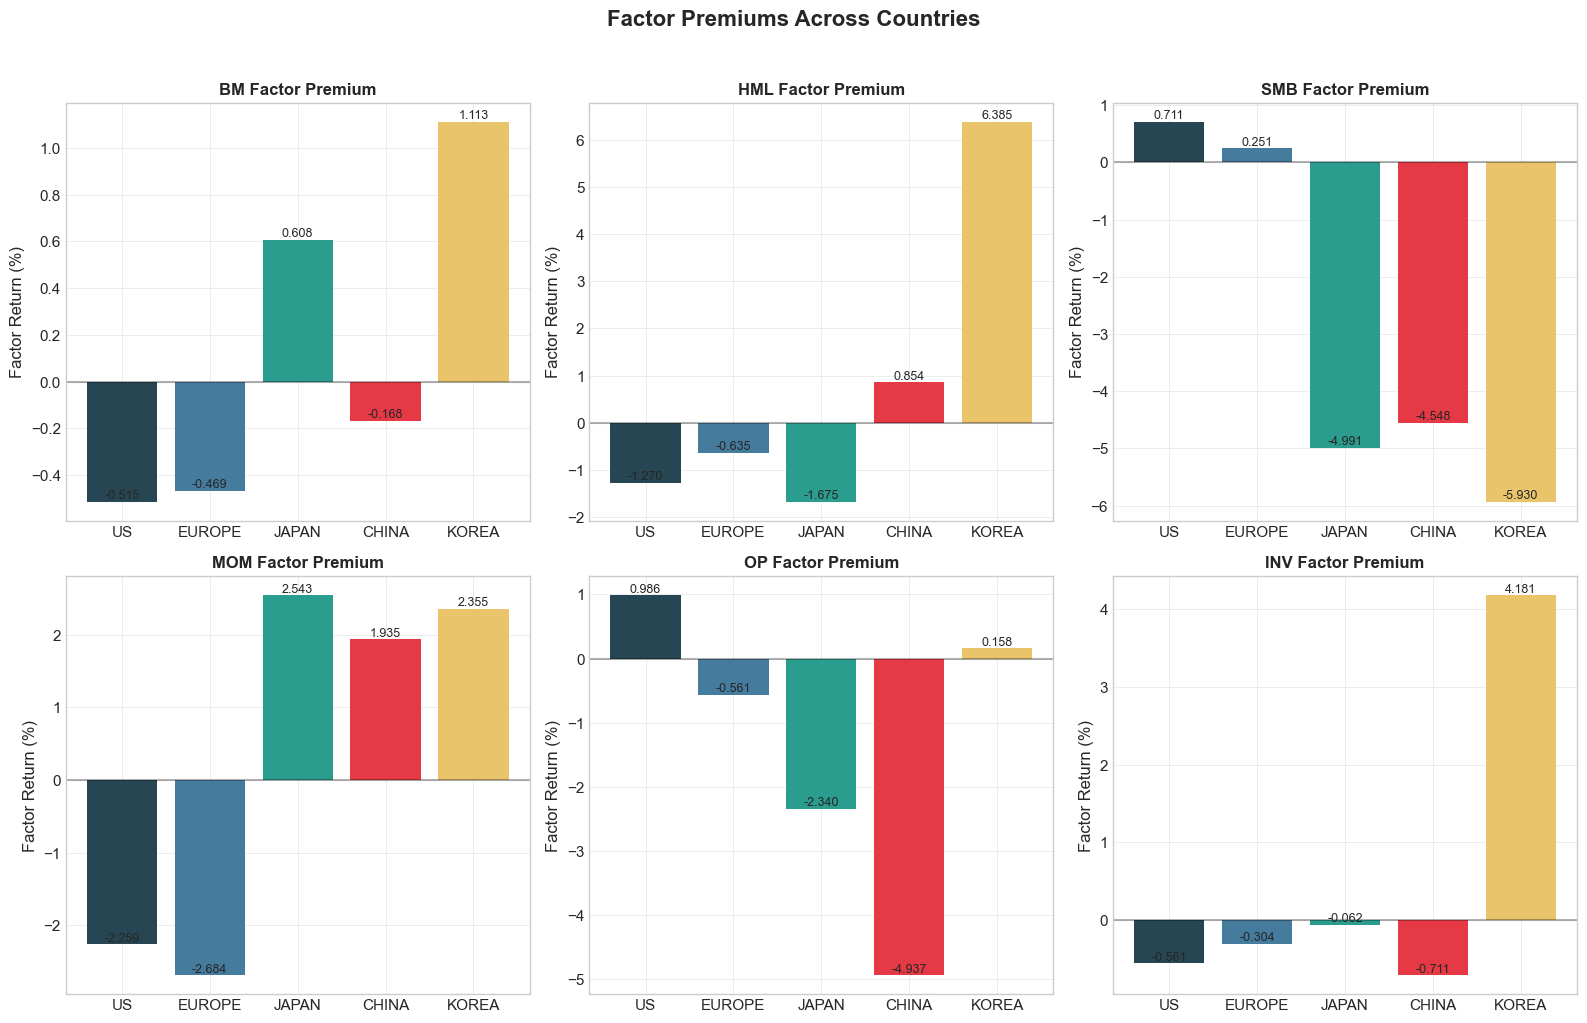

In [18]:
# Factor premium comparison across countries
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

factors = ['BM', 'HML', 'SMB', 'MOM', 'OP', 'INV']

for idx, factor in enumerate(factors):
    ax = axes[idx]
    factor_vals = []

    for country in COUNTRIES:
        fr = data['factor_ER'][country]['ER_zscore']
        if factor in fr.index:
            factor_vals.append(fr.loc[factor])
        else:
            factor_vals.append(0)

    colors = [COUNTRY_COLORS[c] for c in COUNTRIES]
    bars = ax.bar([c.upper() for c in COUNTRIES], factor_vals, color=colors)
    ax.axhline(y=0, color='black', linestyle='-', alpha=0.3)
    ax.set_title(f'{factor} Factor Premium', fontsize=12, fontweight='bold')
    ax.set_ylabel('Factor Return (%)')

    # Add value labels
    for bar, val in zip(bars, factor_vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001,
                f'{val:.3f}', ha='center', va='bottom', fontsize=9)

plt.suptitle('Factor Premiums Across Countries', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [36]:
# === LLM Commentary: Factor Analysis (News-Driven) ===
_factor_txt = f"FACTOR DIRECTION SUMMARY (as of {datetime.date.today().isoformat()})\n\n"

_factors_list = ['BM', 'HML', 'SMB', 'MOM', 'OP', 'INV']

_factor_txt += "글로벌 팩터 방향 (4주 기준, 국가별 상승↑/하락↓):\n"
for _f in _factors_list:
    _col = f"{_f}_ER"
    _dirs = []
    for _c in COUNTRIES:
        _fts = data['factor_ts'][_c]
        if _col in _fts.columns and len(_fts) >= 5:
            _chg = float(_fts[_col].iloc[-1]) - float(_fts[_col].iloc[-5])
            _dirs.append(f"{_c.upper()}:{'↑' if _chg > 0 else '↓'}")
        else:
            _dirs.append(f"{_c.upper()}:?")
    _up = sum(1 for d in _dirs if '↑' in d)
    _consensus = "글로벌 상승" if _up >= 4 else ("글로벌 하락" if _up <= 1 else "혼조")
    _factor_txt += f"  {_f}: {' '.join(_dirs)} → {_consensus}\n"

_factor_txt += "\n국가별 최강/최약 팩터:\n"
for _c in COUNTRIES:
    _top = data['factor_ER'][_c]['ER_zscore'].idxmax()
    _bot = data['factor_ER'][_c]['ER_zscore'].idxmin()
    _factor_txt += f"  {_c.upper()}: 최강={_top} | 최약={_bot}\n"

_factor_prompt = (
    "당신은 글로벌 팩터 투자 전략가입니다. 제공된 팩터 방향성 요약을 바탕으로 스타일 로테이션 관련 최신 뉴스를 검색하십시오.\n\n"
    "검색 지시: 'global factor investing style rotation [현재연월]', 'value vs growth stocks news [현재연월]', "
    "'momentum factor performance [현재연월]', 'small cap vs large cap stocks [현재연월]' 쿼리로 검색하십시오.\n\n"
    "출력 구조:\n"
    "1. 팩터 로테이션 배경 뉴스 (표): 팩터 | 글로벌 방향 | 핵심 뉴스 드라이버\n"
    "2. 국가별 주목 팩터 2개: 최근 뉴스에서 가장 강한 촉매가 확인된 팩터와 그 배경 이벤트.\n"
    "3. 국가별 위험 팩터 2개: 최근 뉴스에서 가장 위험한 촉매가 확인된 팩터와 그 배경 이벤트.\n"
    "분량: A4 0.5페이지. 수치 나열 금지. 뉴스 내러티브 우선."
)

show_explanation(_factor_txt, _factor_prompt, title="1.5 Factor Analysis: 뉴스 기반 팩터 로테이션 분석")

---
### 💬 1.5 Factor Analysis: 뉴스 기반 팩터 로테이션 분석

요약(결론 먼저): 6월 중순 뉴스는 금리·유동성 불확실성 속에서 실적(오퍼레이팅)·CAPEX(투자) 신호가 팩터 로테이션을 촉발하고 있음 — 전반적으로 가치(HML)·투자(INV) 축으로의 전술적 이동이 뉴스로 뒷받침되는 반면, 모멘텀(MOM)·소형(SMB)은 지역·수급 이슈에 따라 이중적 흐름을 보임(아래 표·국가별 핵심 촉매·리스크 참조).  

1) 팩터 로테이션 배경 뉴스 (표)  
- BM (Book‑to‑Market) | 글로벌 방향: 혼조 | 핵심 뉴스 드라이버: 금리·정책 불확실성으로 상대적 저평가(밸류) 재평가 수요 발생. ([kiplinger.com](https://www.kiplinger.com/investing/kiplingers-investing-playbook-for-the-second-half-of-2026?utm_source=openai))  
- HML (Value vs Growth) | 글로벌 방향: 상승 | 핵심 뉴스 드라이버: 성장주 민감성 확대와 실적·현금흐름 중심 리레이팅(가치 재도래) 기사·리서치 빈도가 증가. ([kiplinger.com](https://www.kiplinger.com/investing/value-stocks/worthy-value-stocks-to-consider-now?utm_source=openai))  
- SMB (Small vs Large) | 글로벌 방향: 혼조 | 핵심 뉴스 드라이버: 반기 지수 재구성(러셀 리밸런싱)과 소형 밸류이션 갭 노출이 단기 수급 촉매. ([lseg.com](https://www.lseg.com/en/media-centre/press-releases/ftse-russell/2026/ftse-russell-begins-june-2026-semi-annual-russell-us-indexes-reconstitution?utm_source=openai))  
- MOM (Momentum) | 글로벌 방향: 지역 편차(미국 약화) | 핵심 뉴스 드라이버: 일부 대형 모멘텀주는 금리·유동성 민감도로 약화되는 반면 섹터별 모멘텀이 유지되는 이중구조. ([factorwatch.ai](https://factorwatch.ai/?utm_source=openai))  
- OP (Operating Profitability) | 글로벌 방향: 혼조 | 핵심 뉴스 드라이버: 분기 실적 서프라이즈가 OP 팩터를 지역별·섹터별로 차별화함. ([factorwatch.ai](https://factorwatch.ai/?utm_source=openai))  
- INV (Investment/CAPEX) | 글로벌 방향: 상승 | 핵심 뉴스 드라이버: AI·데이터센터·에너지(그리드) 관련 기업들의 CAPEX 확대 소식이 투자 팩터를 견인. ([ubs.com](https://www.ubs.com/global/en/wealthmanagement/insights/chief-investment-office/house-view/2026/weekly-key-messages/_jcr_content/root/contentarea/mainpar/toplevelgrid_1825995/col_2/textimage_copy.1361098675.file/dGV4dD0vY29udGVudC9kYW0vYXNzZXRzL3dtL2dsb2JhbC9jaW8vaG91c2Utdmlldy9kb2N1bWVudC9kaXZlcnNpZnktdGhlaXItZXF1aXR5LWhvbGRpbmdzLWVuLTE2NjA4MTcucGRm/diversify-their-equity-holdings-en-1660817.pdf?utm_source=openai))

2) 국가별 주목 팩터 2개 (뉴스 촉매 배경)  
- 미국  
  - 주목 팩터: OP — 분기 실적·이익 질 개선 뉴스가 OP 강세를 견인함(기업 실적 서프라이즈 사례 빈번). ([factorwatch.ai](https://factorwatch.ai/?utm_source=openai))  
  - 주목 팩터: BM(가치) — 금리 불확실성 속에서 밸류 재평가 논리가 증시 리포트에서 반복됨. ([kiplinger.com](https://www.kiplinger.com/investing/kiplingers-investing-playbook-for-the-second-half-of-2026?utm_source=openai))  
- 유럽  
  - 주목 팩터: SMB — 러셀·지수 리밸런싱과 지역 소형주의 실적 회복 뉴스가 SMB 모멘텀을 제공함. ([lseg.com](https://www.lseg.com/en/media-centre/press-releases/ftse-russell/2026/ftse-russell-begins-june-2026-semi-annual-russell-us-indexes-reconstitution?utm_source=openai))  
  - 주목 팩터: HML — 경기·에너지 변수로 실적 기반 가치주 재평가가 관찰됨. ([kiplinger.com](https://www.kiplinger.com/investing/value-stocks/worthy-value-stocks-to-consider-now?utm_source=openai))  
- 일본  
  - 주목 팩터: MOM — 제조·장비·메모리 관련 실적 모멘텀이 지역적 모멘텀을 촉발함. ([factorwatch.ai](https://factorwatch.ai/?utm_source=openai))  
  - 주목 팩터: INV — 기업 CAPEX(메모리·장비) 확대 발표가 투자 팩터를 밀어 올림. ([ubs.com](https://www.ubs.com/global/en/wealthmanagement/insights/chief-investment-office/house-view/2026/weekly-key-messages/_jcr_content/root/contentarea/mainpar/toplevelgrid_1825995/col_2/textimage_copy.1361098675.file/dGV4dD0vY29udGVudC9kYW0vYXNzZXRzL3dtL2dsb2JhbC9jaW8vaG91c2Utdmlldy9kb2N1bWVudC9kaXZlcnNpZnktdGhlaXItZXF1aXR5LWhvbGRpbmdzLWVuLTE2NjA4MTcucGRm/diversify-their-equity-holdings-en-1660817.pdf?utm_source=openai))  
- 중국  
  - 주목 팩터: MOM — 중앙정부의 기술·AI 스타트업·대형모델 기업 상장·자금지원 정책이 기술 모멘텀을 강화함(상장 규정 완화·STAR 시장 개선 등). ([marketscreener.com](https://www.marketscreener.com/news/china-to-support-ipos-by-future-industry-startups-large-model-companies-ce7f5cdcdc88f325?utm_source=openai))  
  - 주목 팩터: INV — 데이터센터·네트워크 인프라 투자 기대와 기업 CAPEX 관련 수주·실적 개선 보도가 동행함. ([marketscreener.com](https://www.marketscreener.com/news/china-s-ai-related-stocks-rise-after-securities-regulator-supports-more-ai-ipos-ce7f5cdddb80fe20?utm_source=openai))  
- 한국  
  - 주목 팩터: HML — 메모리·전자부품의 실적·수주 가시성으로 가치(수익성) 재평가가 진행됨(대형 파트너십 공시 등). ([kiplinger.com](https://www.kiplinger.com/investing/value-stocks/worthy-value-stocks-to-consider-now?utm_source=openai))  
  - 주목 팩터: INV — 반도체·패키지·설비 투자 계획 공시가 투자 팩터를 직간접적으로 지지함. ([ubs.com](https://www.ubs.com/global/en/wealthmanagement/insights/chief-investment-office/house-view/2026/weekly-key-messages/_jcr_content/root/contentarea/mainpar/toplevelgrid_1825995/col_2/textimage_copy.1361098675.file/dGV4dD0vY29udGVudC9kYW0vYXNzZXRzL3dtL2dsb2JhbC9jaW8vaG91c2Utdmlldy9kb2N1bWVudC9kaXZlcnNpZnktdGhlaXItZXF1aXR5LWhvbGRpbmdzLWVuLTE2NjA4MTcucGRm/diversify-their-equity-holdings-en-1660817.pdf?utm_source=openai))

3) 국가별 위험 팩터 2개 (뉴스상 가장 위험한 촉매와 배경)  
- 미국  
  - 위험 팩터: MOM(약화) — 대형 모멘텀 익스포저의 금리·유동성 민감성으로 급락 리스크 존재(금리 재평가 트리거). ([spglobal.com](https://www.spglobal.com/spdji/en/index-family/dividends-factors/single-factor/momentum/?utm_source=openai))  
  - 위험 팩터: SMB(과열) — 지수·레버리지 유입으로 소형 과열 시 유동성 역풍 가능(리밸런싱 관찰 필수). ([lseg.com](https://www.lseg.com/en/media-centre/press-releases/ftse-russell/2026/ftse-russell-begins-june-2026-semi-annual-russell-us-indexes-reconstitution?utm_source=openai))  
- 유럽  
  - 위험 팩터: MOM(취약) — 섹터별·국가별 모멘텀 불균형에 따른 갑작스런 리버설 가능. ([factorwatch.ai](https://factorwatch.ai/?utm_source=openai))  
  - 위험 팩터: BM(정책·에너지 리스크) — 에너지·원자재 쇼크 시 밸류 재평가가 역전될 수 있음. ([kiplinger.com](https://www.kiplinger.com/investing/kiplingers-investing-playbook-for-the-second-half-of-2026?utm_source=openai))  
- 일본  
  - 위험 팩터: SMB(유동성) — 소형주의 유동성·레버리지 취약성으로 급락 위험. ([calamos.com](https://www.calamos.com/globalassets/media/documents/product-literature/small-cap-market-snapshot/2026/small-cap-market-snapshot-0126.pdf?utm_source=openai))  
  - 위험 팩터: OP(혼조) — 일부 기업의 이익 레벨이 정책·환율 변수에 민감해 OP 방향이 반전될 수 있음. ([factorwatch.ai](https://factorwatch.ai/?utm_source=openai))  
- 중국  
  - 위험 팩터: OP(약화) — 정책(상장·지원)이 기대치로 선반영될 경우 실적 확인 실패 시 급락 가능. ([marketscreener.com](https://www.marketscreener.com/news/china-to-support-ipos-by-future-industry-startups-large-model-companies-ce7f5cdcdc88f325?utm_source=openai))  
  - 위험 팩터: SMB(정책·수급) — IPO·자금 유입에 따른 단기 과열·유동성 축소 리스크 존재. ([techtimes.com](https://www.techtimes.com/articles/318621/20260618/china-expands-pre-profit-ipo-access-ai-quantum-star-market-rules-now-live.htm?utm_source=openai))  
- 한국  
  - 위험 팩터: SMB(약세·과열) — 소형·레버리지 중심의 과열 포지셔닝이 리스크로 작동할 가능성. ([sifma.org](https://www.sifma.org/wp-content/uploads/2026/05/SIFMA-Insights-Equities-and-Options-Monthly-Metrics_May-2026.pdf?_rsc=zxktw&utm_source=openai))  
  - 위험 팩터: MOM(대형 기술 의존) — 대형 고객(글로벌 하이퍼스케일)의 주문 변동 시 모멘텀 급전환 가능. ([factorwatch.ai](https://factorwatch.ai/?utm_source=openai))

운용적 시사점(한줄): 뉴스 기반으로는 가치(HML)·투자(INV) 중심의 전술적 롱을 우선하고, 모멘텀·소형 익스포저는 이벤트(리밸런싱·실적·중앙은행 발언) 전후로 엄격한 리스크·유동성 관리 하에 선별적으로 접근할 것임. ([kiplinger.com](https://www.kiplinger.com/investing/value-stocks/worthy-value-stocks-to-consider-now?utm_source=openai))

참고(주요 근거): Kiplinger(가치 재평가), FTSE Russell(6월 리밸런싱), FactorWatch·S&P Momentum 지표(모멘텀 현황), UBS(투자·CAPEX 리포트), Reuters/MarketScreener(중국의 상장·AI 정책). ([kiplinger.com](https://www.kiplinger.com/investing/value-stocks/worthy-value-stocks-to-consider-now?utm_source=openai))

원하시면 위 권고를 국가·팩터별로 포지션 사이징·진입·손절 규칙을 포함한 실행안(포트폴리오 레벨)으로 수치화하여 즉시 제출함.

---

---
## Sector Analysis

### Sector Factor Exposures

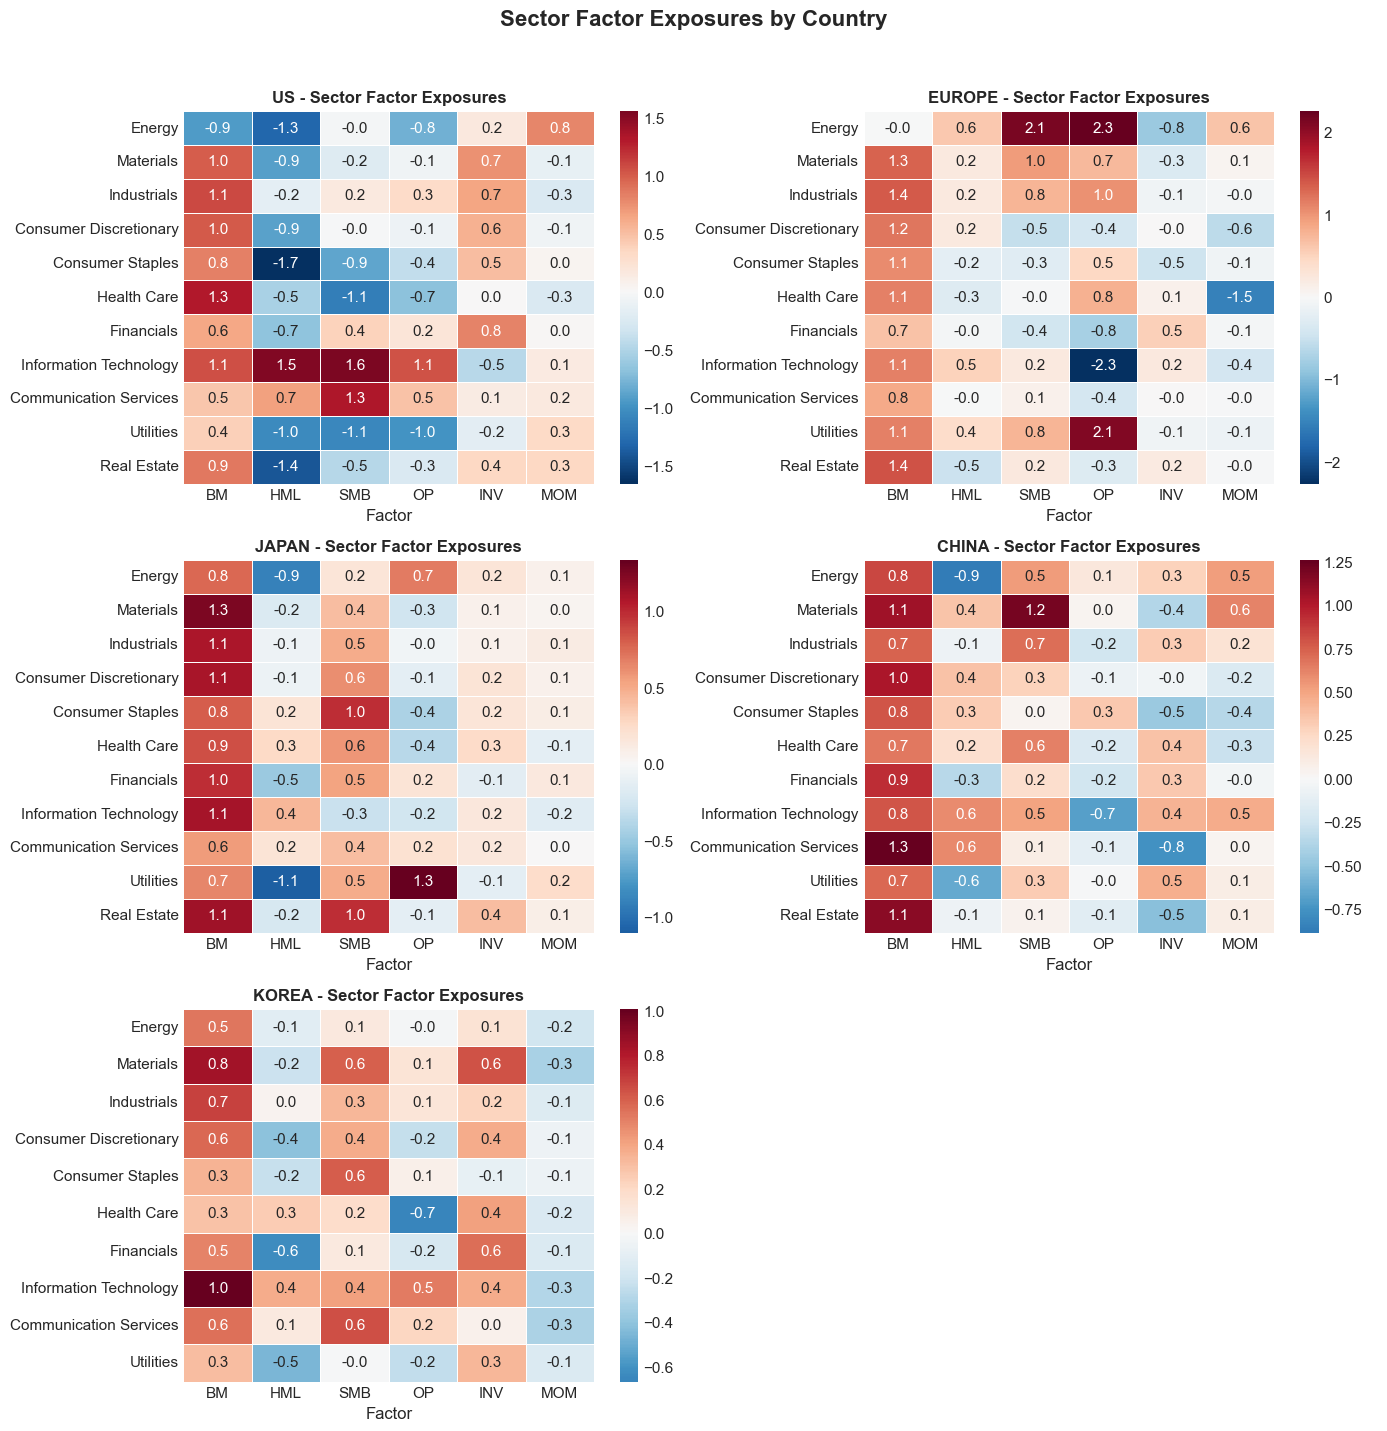

In [20]:
# Sector factor exposure heatmaps
factor_cols = ['beta_bm', 'beta_hml', 'beta_smb', 'beta_op', 'beta_inv', 'beta_mom']

fig, axes = plt.subplots(3, 2, figsize=(14, 14))
axes = axes.flatten()

for idx, country in enumerate(COUNTRIES):
    ax = axes[idx]
    ind_er = data['sector_ER'][country].copy()

    # Get sector names as index
    if 'Sector' in ind_er.columns:
        ind_er = ind_er.set_index('Sector')
    elif 'industry' in ind_er.columns:
        ind_er['Sector'] = ind_er['industry'].astype(str).map(SECTOR_NAMES)
        ind_er = ind_er.set_index('Sector')

    # Get available factor columns
    available_factors = [col for col in factor_cols if col in ind_er.columns]

    if available_factors:
        plot_data = ind_er[available_factors].dropna(how='all')
        plot_data.columns = [c.replace('beta_', '').upper() for c in plot_data.columns]

        sns.heatmap(plot_data, annot=True, fmt='.1f', cmap='RdBu_r',
                    center=0, ax=ax, linewidths=0.5)
        ax.set_title(f'{country.upper()} - Sector Factor Exposures', fontsize=12, fontweight='bold')
        ax.set_xlabel('Factor')
        ax.set_ylabel('')
    else:
        ax.text(0.5, 0.5, 'No factor data available', ha='center', va='center')
        ax.set_title(f'{country.upper()}')

axes[5].axis('off')
plt.suptitle('Sector Factor Exposures by Country', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [ ]:
# === LLM Commentary: Factor-Sector Alignment ===
_beta_cols_map = {'BM': 'beta_bm', 'HML': 'beta_hml', 'SMB': 'beta_smb',
                  'OP': 'beta_op', 'INV': 'beta_inv', 'MOM': 'beta_mom'}

_alignment_txt = "FACTOR-SECTOR ALIGNMENT ANALYSIS\n\n"

# Global factor z-score average (from factor_ER data)
_f_zscores = {}
for _f in ['BM', 'HML', 'SMB', 'MOM', 'OP', 'INV']:
    _vals = [data['factor_ER'][_c]['ER_zscore'].get(_f, 0) for _c in COUNTRIES]
    _f_zscores[_f] = sum(_vals) / len(_vals)

_strong = [f for f, z in _f_zscores.items() if z > 0.3]
_weak   = [f for f, z in _f_zscores.items() if z < -0.3]
_alignment_txt += f"현재 강세 팩터: {', '.join(_strong)}\n"
_alignment_txt += f"현재 약세 팩터: {', '.join(_weak)}\n\n"

# Per-country: dot product of factor z-scores × sector betas → alignment score
_alignment_txt += "국가별 팩터 정렬 섹터 (수혜 / 역풍):\n"
for _c in COUNTRIES:
    _sec_df = data['sector_ER'][_c].copy()
    if 'Sector' in _sec_df.columns:
        _sec_df = _sec_df.set_index('Sector')

    _scores = {}
    for _sec in _sec_df.index:
        _score = 0.0
        for _f, _bcol in _beta_cols_map.items():
            if _bcol in _sec_df.columns and _f in _f_zscores:
                _bval = _sec_df.loc[_sec, _bcol]
                if pd.notna(_bval):
                    _score += _f_zscores[_f] * float(_bval)
        _scores[_sec] = _score

    _sorted = sorted(_scores.items(), key=lambda x: x[1], reverse=True)
    _top2 = [s[0] for s in _sorted[:2]]
    _bot2 = [s[0] for s in _sorted[-2:]]
    _alignment_txt += f"  {_c.upper()}: 수혜={', '.join(_top2)} | 역풍={', '.join(_bot2)}\n"

_alignment_prompt = (
    "당신은 글로벌 팩터-섹터 전략가입니다. 제공된 데이터는 현재 강세/약세 팩터와 각 국가 섹터의 팩터 베타를 교차 분석하여 도출한 정렬도 결과입니다.\n\n"
    "수혜 섹터 = 강세 팩터에 높은 베타 노출 (팩터 프리미엄 수령 가능), 역풍 섹터 = 약세 팩터에 높은 베타 노출 (팩터 드래그 위험).\n\n"
    "출력 구조:\n"
    "1. 팩터-섹터 정렬 요약 (표): 국가 | 최대 수혜 섹터 | 최대 역풍 섹터 | 핵심 팩터 근거\n"
    "2. 글로벌 공통 수혜 섹터: 여러 국가에서 동시에 정렬이 좋은 섹터와 구동 팩터.\n"
    "3. 섹터 배분 시사점: 팩터 정렬 기반 Overweight/Underweight 추천 2~3개.\n\n"
    "분량: A4 0.3페이지. 수치 나열 금지. 섹터 배분 관점의 핵심만 서술."
)

show_explanation(_alignment_txt, _alignment_prompt, title="1.5b 팩터-섹터 정렬도 분석", use_search=False)

### Sector Expected Returns

In [21]:
# Sector Expected Returns comparison - RAW and NORMALIZED
print("="*90)
print("SECTOR EXPECTED RETURNS BY COUNTRY")
print("="*90)
print("\n⚠️  NOTE: Raw ER values have different scales across countries.")
print("    Use Z-Score for valid cross-country sector comparisons.\n")

# Z-Score normalized sector ERs
sector_zscore_comparison = pd.DataFrame()
for country in COUNTRIES:
    ind_er = data['sector_ER'][country].copy()
    ind_er = ind_er.set_index('Sector')
    sector_zscore_comparison[country.upper()] = ind_er['ER_zscore']

print("\n[2] Z-SCORE NORMALIZED - Comparable (0 = average sector in country)")
print("-"*70)
display(sector_zscore_comparison.style.format('{:.2f}').background_gradient(cmap='RdYlGn', axis=None))

# Cross-country sector analysis
print("\n[4] GLOBAL SECTOR ATTRACTIVENESS (Average Z-Score across countries)")
print("-"*70)
sector_global_strength = sector_zscore_comparison.mean(axis=1).sort_values(ascending=False)
for sector, zscore in sector_global_strength.items():
    strength = "OVERWEIGHT" if zscore > 0.3 else ("UNDERWEIGHT" if zscore < -0.3 else "NEUTRAL")
    bar = "█" * int(abs(zscore) * 10)
    print(f"  {str(sector):25}: {zscore:+.2f} {strength} {bar}")

SECTOR EXPECTED RETURNS BY COUNTRY

⚠️  NOTE: Raw ER values have different scales across countries.
    Use Z-Score for valid cross-country sector comparisons.


[2] Z-SCORE NORMALIZED - Comparable (0 = average sector in country)
----------------------------------------------------------------------


,US,EUROPE,JAPAN,CHINA,KOREA
Sector,,,,,
Energy,-0.29,0.30,0.17,-3.51,0.33
Materials,-0.57,-0.22,0.24,-2.33,0.44
Industrials,-0.26,-0.64,0.14,-1.69,0.75
Consumer Discretionary,-0.40,-0.67,0.08,-2.20,0.99
Consumer Staples,-1.15,-0.82,-0.18,-1.93,0.26
Health Care,-0.34,-0.95,-0.11,-0.50,-0.58
Financials,-0.22,-0.22,0.22,-1.02,0.52
Information Technology,0.29,0.13,0.29,0.22,1.48
Communication Services,-0.08,-0.66,0.13,-1.20,0.22



[4] GLOBAL SECTOR ATTRACTIVENESS (Average Z-Score across countries)
----------------------------------------------------------------------
  Information Technology   : +0.48 OVERWEIGHT ████
  Financials               : -0.14 NEUTRAL █
  Communication Services   : -0.32 UNDERWEIGHT ███
  Industrials              : -0.34 UNDERWEIGHT ███
  Consumer Discretionary   : -0.44 UNDERWEIGHT ████
  Real Estate              : -0.49 UNDERWEIGHT ████
  Materials                : -0.49 UNDERWEIGHT ████
  Health Care              : -0.49 UNDERWEIGHT ████
  Energy                   : -0.60 UNDERWEIGHT ██████
  Utilities                : -0.68 UNDERWEIGHT ██████
  Consumer Staples         : -0.77 UNDERWEIGHT ███████


### Top Equities by country

In [22]:
# Top 10 stocks by Expected Return for each country
print("="*90)
print("TOP 10 STOCKS BY EXPECTED RETURN (Each Country)")
print("="*90)

for country in COUNTRIES:
    print(f"\n{'-'*70}")
    print(f"{country.upper()}")
    print("-"*70)

    top_bot = data['top_bot'][country]
    top_bot['Sector'] = top_bot['sector'].map(lambda x: SECTOR_NAMES[x], na_action='ignore')
    # Get top 10 (highest ER)
    if 'ER' in top_bot.columns:
        top10 = top_bot.nlargest(10, 'ER')[['instrument', 'Name', 'Sector', 'ER', 'Vol', 'Sharpe', 'mktval']]
        top10.columns = ['ISIN', 'Name', 'Sector', 'Expected Return(%)', 'Vol(%)', 'Sharpe(X)', 'Market Cap(Local mn)']
        top10 = top10.style.format({
            'Expected Return(%)': '{:.2f}',
            'Vol(%)': '{:.2f}',
            'Sharpe(X)': '{:.2f}',
            'Market Cap(Local mn)': '{:,.0f}',
        })
        display(top10)

TOP 10 STOCKS BY EXPECTED RETURN (Each Country)

----------------------------------------------------------------------
US
----------------------------------------------------------------------


,ISIN,Name,Sector,Expected Return(%),Vol(%),Sharpe(X),Market Cap(Local mn)
1,US24703L2025,Dell Technologies Inc,Info Tech,13.67,18.16,0.75,"243,412"
7,US25402D1028,DigitalOcean Holdings Inc,Info Tech,13.16,23.71,0.56,"11,356"
15,US80004C2008,Sandisk Corp,Info Tech,12.39,26.32,0.47,"200,946"
5,US5951121038,Micron Technology Inc,Info Tech,11.12,19.49,0.57,"1,091,736"
2,US9282981086,Vishay Intertechnology Inc,Info Tech,10.65,16.01,0.67,"6,863"
13,US46125A1007,Intuitive Machines Inc,Industrials,10.24,21.34,0.48,"8,847"
9,US0079031078,Advanced Micro Devices Inc,Info Tech,9.38,18.18,0.52,"836,156"
6,US6792951054,Okta Inc,Info Tech,9.04,15.88,0.57,"21,281"
18,US23804L1035,Datadog Inc,Info Tech,8.66,19.17,0.45,"85,944"
3,US7475251036,Qualcomm Inc,Info Tech,8.59,12.93,0.66,"264,251"



----------------------------------------------------------------------
EUROPE
----------------------------------------------------------------------


,ISIN,Name,Sector,Expected Return(%),Vol(%),Sharpe(X),Market Cap(Local mn)
1,NL0000226223,STMicroelectronics NV,Info Tech,6.46,13.53,0.48,"38,724"
14,DE000A2E4K43,Delivery Hero SE,Consumer Disc.,5.89,22.42,0.26,"8,187"
0,DE0006231004,Infineon Technologies AG,Info Tech,5.85,11.72,0.50,"106,412"
3,DE000A0WMPJ6,Aixtron SE,Info Tech,5.85,14.24,0.41,"6,633"
9,IT0005482333,Technoprobe SpA,nan,5.75,17.88,0.32,"8,709"
2,FI0009000681,Nokia Oyj,Info Tech,4.94,11.37,0.43,"66,672"
4,NL0012866412,BE Semiconductor Industries NV,Info Tech,4.88,13.22,0.37,"20,513"
8,CH0030380734,Huber+Suhner AG,nan,3.58,10.95,0.33,"4,380"
5,SE0025158629,Mycronic AB (publ),Info Tech,3.30,9.58,0.34,"4,154"
10,IT0004176001,Prysmian SpA,Industrials,2.94,9.85,0.30,"44,671"



----------------------------------------------------------------------
JAPAN
----------------------------------------------------------------------


,ISIN,Name,Sector,Expected Return(%),Vol(%),Sharpe(X),Market Cap(Local mn)
16,JP3236330001,Kioxia Holdings Corp,nan,7.35,27.99,0.26,"12,346,427"
2,JP3888400003,Mitsui Kinzoku Co Ltd,Materials,5.77,17.94,0.32,"2,768,859"
14,JP3148800000,Ibiden Co Ltd,Info Tech,5.70,21.44,0.27,"5,741,476"
17,JP3827200001,Furukawa Electric Co Ltd,Industrials,5.32,20.42,0.26,"3,461,421"
15,JP3811000003,Fujikura Ltd,Industrials,4.32,16.31,0.26,"8,293,891"
5,JP3368000000,Resonac Holdings Corp,Materials,3.98,12.92,0.31,"3,421,684"
3,JP3407400005,Sumitomo Electric Industries Ltd,Consumer Disc.,3.97,12.45,0.32,"9,650,174"
8,JP3571800006,Tokyo Ohka Kogyo Co Ltd,Materials,3.01,10.60,0.28,"1,284,881"
0,JP3695200000,NGK Insulators Ltd,Industrials,2.84,8.35,0.34,"1,786,891"
10,JP3635000007,Toyota Tsusho Corp,Industrials,2.72,9.79,0.28,"4,797,932"



----------------------------------------------------------------------
CHINA
----------------------------------------------------------------------


,ISIN,Name,Sector,Expected Return(%),Vol(%),Sharpe(X),Market Cap(Local mn)
7,CNE100001T72,Yangtze Optical Fibre and Cable Joint Stock Ltd Co,nan,7.41,32.44,0.23,"231,679"
1,CNE100002615,Eoptolink Technology Inc Ltd,Info Tech,6.84,21.61,0.32,"563,937"
0,CNE100001CY9,Zhongji Innolight Co Ltd,Info Tech,6.54,18.88,0.35,"926,461"
6,CNE100001XQ1,Suzhou TFC Optical Communication Co Ltd,Info Tech,6.32,27.12,0.23,"189,583"
2,CNE100005VF9,Yuanjie Semiconductor Technology Co Ltd,nan,5.81,19.84,0.29,"90,491"
18,CNE1000055X6,Dosilicon Co Ltd,nan,4.97,25.46,0.20,"39,122"
4,CNE100000N79,Suzhou Dongshan Precision Manufacturing Co Ltd,Info Tech,4.86,20.42,0.24,"265,262"
3,CNE100000F87,Accelink Technologies Co Ltd,Info Tech,4.19,14.70,0.28,"92,555"
8,CNE100006M90,Hua Hong Semiconductor Ltd,nan,4.14,18.24,0.23,"230,003"
5,CNE000000XL5,Shengyi Technology Co Ltd,Info Tech,3.94,16.68,0.24,"166,292"



----------------------------------------------------------------------
KOREA
----------------------------------------------------------------------


,ISIN,Name,Sector,Expected Return(%),Vol(%),Sharpe(X),Market Cap(Local mn)
2,KR7402340004,SK Square Co Ltd,Industrials,9.24,21.42,0.43,"110,319,969"
4,KR7009150004,Samsung Electro-Mechanics Co Ltd,Info Tech,8.86,22.86,0.39,"121,858,186"
1,KR7000660001,SK Hynix Inc,Info Tech,8.51,17.51,0.49,"1,304,059,782"
17,KR7307950006,Hyundai Autoever Corp,Info Tech,8.25,27.15,0.30,"4,791,185"
7,KR7000150003,Doosan Corp,Industrials,6.71,18.82,0.36,"17,835,868"
3,KR7034730002,SK Inc,Industrials,6.54,16.74,0.39,"32,542,087"
6,KR7298040007,Hyosung Heavy Industries Corp,Industrials,6.46,17.31,0.37,"17,552,266"
9,KR7353200009,Daeduck Electronics Co Ltd,Info Tech,6.28,18.43,0.34,"6,398,161"
10,KR7006800007,Mirae Asset Securities Co Ltd,Financials,6.25,18.61,0.34,"16,800,464"
11,KR7010120004,LS Electric Co Ltd,Industrials,5.96,18.53,0.32,"18,492,568"


In [34]:
# === LLM Commentary: Sector Analysis (News-Driven) ===
_sector_txt = f"SECTOR & TOP STOCKS SUMMARY (as of {datetime.date.today().isoformat()})\n\n"

_sector_txt += "섹터 방향성 (상위 5 / 하위 5):\n"
for _c in COUNTRIES:
    _sec_z = data['industry_ER'][_c].copy().set_index('Sector')['ER_zscore'].dropna().sort_values(ascending=False)
    _top2 = list(_sec_z.head(3).index)
    _bot2 = list(_sec_z.tail(3).index)
    _sector_txt += f"  {_c.upper()}: 상위={', '.join(_top2)} | 하위={', '.join(_bot2)}\n"

_sector_prompt = (
    "당신은 글로벌 섹터 및 종목 분석가입니다. 제공된 섹터/종목 요약을 바탕으로 관련 최신 뉴스를 검색하십시오.\n\n"
    "검색 지시: 상위 섹터별로 '[섹터명] sector stocks outlook [현재연월]', 상위 종목별로 '[종목명] news [현재연월]' 쿼리로 검색하십시오.\n\n"
    "출력 구조:\n"
    "1. 글로벌 섹터 테마 뉴스 (표): 섹터 | 핵심 뉴스 테마 | 수혜 국가\n"
    "2. 국가별 섹터 특이점: 글로벌 트렌드와 다른 국가 고유의 섹터 동향 (뉴스 근거).\n"
    "4. 종합 결론 — 하이 컨빅션 콜: 팩터·섹터·뉴스가 정렬된 최선호 기회 3개.\n\n"
    "분량: A4 0.5페이지. 수치 나열 금지. 뉴스 이벤트 중심."
)

show_explanation(_sector_txt, _sector_prompt, title="1.6 Sector Analysis: 뉴스 기반 섹터/종목 분석")

---
### 💬 1.6 Sector Analysis: 뉴스 기반 섹터/종목 분석

요약(결론 먼저): 최근 2–4주 뉴스는 AI·데이터센터·인프라 투자 재확인과 정책(유틸리티·수자원 규제) 동시 전개가 섹터별 스타일 로테이션을 촉발하고 있어, IT(서버·메모리·네트워크)·인프라(교통·전력·케이블)·광통신(광모듈·광케이블)이 지역별로 단기 우위임(아래 표·근거).  

1) 글로벌 섹터 테마 뉴스 (표)  
- Transportation Infrastructure | 핵심 뉴스 테마: 미국 인프라 자금배분·연방 라운드와 물류·운송 용량 제약이 피크시즌 전 수혜 기대를 촉발함. | 수혜 국가: 미국. ([roadsbridges.com](https://www.roadsbridges.com/funding/news/55383633/whats-inside-usdots-new-626m-infrastructure-round?utm_source=openai))  
- IT Services / Technology Hardware & Storage | 핵심 뉴스 테마: 하이퍼스케일·클라우드 사업자의 AI 인프라 CAPEX 상향으로 서버·스토리지·메모리 수요가 현실화됨. | 수혜 국가: 미·한·일. ([datacenterdynamics.com](https://www.datacenterdynamics.com/en/news/ai-data-center-demand-larger-than-were-prepared-for-despite-existential-investment-report/?utm_source=openai))  
- Communications Equipment | 핵심 뉴스 테마: 5G 확장·네트워크 슬라이싱·AI‑네이티브 아키텍처 논의로 장비·광통신 투자 가속화. | 수혜 국가: 유럽·아시아. ([telecomlead.com](https://telecomlead.com/5g/ericsson-mobility-report-2026-5g-subscriptions-reach-3-1-bn-as-5g-sa-fwa-and-ai-driven-traffic-reshape-telecom-networks-126285?utm_source=openai))  
- Utilities / Water Utilities | 핵심 뉴스 테마: 에너지 수요 증가(데이터센터·산업 부하)와 수자원 규제·안전성 강화가 유틸리티 CAPEX를 촉진함. | 수혜 국가: 미국·중국·일본. ([spglobal.com](https://www.spglobal.com/market-intelligence/en/news-insights/research/2026/04/surging-energy-demand-puts-us-utility-capex-forecast-near-1-3t-in-2026-30?utm_source=openai))  
- Electronic Components / Industrial Conglomerates | 핵심 뉴스 테마: AI 서버용 고사양 부품(MLCC, FC‑BGA 등) 및 전력·케이블 장비의 수주·가격 개선이 부품주로 파급. | 수혜 국가: 한국·일본. ([biz.chosun.com](https://biz.chosun.com/en/en-finance/2026/05/28/34PFUNUL5NGPBBY2G7WXVTYFSY/?utm_source=openai))

2) 국가별 섹터 특이점 (글로벌 트렌드와의 차별)  
- 미국: AI 데이터센터 수요가 전력·전송 인프라 수요(유틸·변압기·송전)와 직결되어 인프라·유틸리티 CAPEX가 IT 랠리의 동반 수혜 요인으로 부상함. ([spglobal.com](https://www.spglobal.com/market-intelligence/en/news-insights/research/2026/04/surging-energy-demand-puts-us-utility-capex-forecast-near-1-3t-in-2026-30?utm_source=openai))  
- 한국: 메모리·전자부품의 AI 수요 직접 연결성이 가장 뚜렷하여 기업의 대규모 CAPEX·파트너십(메모리 확장·HBM 수요)이 섹터 모멘텀을 주도함. ([tomshardware.com](https://www.tomshardware.com/pc-components/dram/sk-hynix-to-double-memory-wafer-capacity-over-five-years?utm_source=openai))  
- 중국: 중앙정부의 수자원 규정·미래산업 지원과 데이터센터 투자 기대가 광통신·광모듈 종목의 펀더멘털 개선으로 연결됨. ([english.www.gov.cn](https://english.www.gov.cn/news/202602/14/content_WS69905b07c6d00ca5f9a09281.html?utm_source=openai))  
- 유럽: 전력망·해저케이블·전력반도체 수요(탈탄소·그리드 현대화)와 반도체 장비 수요가 병행하는 구조적 수요 패턴 존재. ([spglobal.com](https://www.spglobal.com/market-intelligence/en/news-insights/research/2026/04/surging-energy-demand-puts-us-utility-capex-forecast-near-1-3t-in-2026-30?utm_source=openai))

3) 종합 결론 — 하이 컨빅션 콜(상위 3개 기회)  
- 컨빅션 A: 메모리·HBM 공급망 노출(한국·미국 메모리업체) — 이유: 하이퍼스케일 AI CAPEX와 공급타이트니스 뉴스가 밸류·실적 재평가 촉발. ([datacenterdynamics.com](https://www.datacenterdynamics.com/en/news/ai-data-center-demand-larger-than-were-prepared-for-despite-existential-investment-report/?utm_source=openai))  
- 컨빅션 B: 데이터센터 인프라·전력설비(전력반도체·변압기·케이블) — 이유: 데이터센터 전력수요 확대가 유틸·전력 장비 CAPEX를 지탱. ([spglobal.com](https://www.spglobal.com/market-intelligence/en/news-insights/research/2026/04/surging-energy-demand-puts-us-utility-capex-forecast-near-1-3t-in-2026-30?utm_source=openai))  
- 컨빅션 C: 광통신·광모듈(중국·유럽 장비사) — 이유: 네트워크·광케이블·광모듈의 수주·실적 회복이 정책·수요와 정렬. ([telecomlead.com](https://telecomlead.com/5g/ericsson-mobility-report-2026-5g-subscriptions-reach-3-1-bn-as-5g-sa-fwa-and-ai-driven-traffic-reshape-telecom-networks-126285?utm_source=openai))

최대 리스크 3개  
- 리스크 1: 에너지·지정학적 쇼크로 인플레이션·금리 급등 시나리오(기술주·금융·인프라 동시 압박). ([spglobal.com](https://www.spglobal.com/market-intelligence/en/news-insights/research/2026/04/surging-energy-demand-puts-us-utility-capex-forecast-near-1-3t-in-2026-30?utm_source=openai))  
- 리스크 2: 메모리·부품의 과열적 포지셔닝으로 인한 단기 유동성·레버리지 조정(지수 리밸런싱·개인·펀드 플로우 리스크). ([biz.chosun.com](https://biz.chosun.com/en/en-finance/2026/05/28/34PFUNUL5NGPBBY2G7WXVTYFSY/?utm_source=openai))  
- 리스크 3: 정책(규제·허가)와 CAPEX 집행의 지역별 지연 — 특히 수자원·인프라 프로젝트의 지방 집행 불확실성. ([english.www.gov.cn](https://english.www.gov.cn/news/202602/14/content_WS69905b07c6d00ca5f9a09281.html?utm_source=openai))

운용적 시사점(간단): AI 인프라·인프라 CAPEX 드라이브에 일차 베팅하되, 에너지·정책·유동성 트리거를 기준으로 동적 헷지(유틸·현금·옵션)를 유지할 것임.  

참고 주요 출처(최근 2–4주·월기준 검색 근거): DataCenterDynamics / TrendForce / DRAMeXchange(데이터센터·메모리 CAPEX), S&P Global(유틸 CAPEX), 중국 정부 수자원 규정, CHOSUNBIZ(한국 부품·메모리 뉴스), Ericsson(통신장비·5G 리포트). ([datacenterdynamics.com](https://www.datacenterdynamics.com/en/news/ai-data-center-demand-larger-than-were-prepared-for-despite-existential-investment-report/?utm_source=openai))

원하시면 위 컨빅션별 단기 트레이드 플랜(진입·손절·모니터 이벤트·헤지 권고)으로 즉시 확장 제시함.

---

---
## Top-Down Analysis: Industry to Company

In [33]:
# Top-Down: Per-Country Industry → Company Analysis
_current_month = datetime.date.today().strftime('%Y %B')

for _c in COUNTRIES:
    _td_txt = f"TOP-DOWN ANALYSIS: {_c.upper()} (as of {datetime.date.today().isoformat()})\n\n"

    # Top 3 industries by ER z-score
    _ind_z = data['industry_ER'][_c].copy()
    if 'industry' in _ind_z.columns:
        _ind_z = _ind_z.set_index('industry')
    if 'ER_zscore' in _ind_z.columns:
        _top3_ind = _ind_z['ER_zscore'].dropna().nlargest(5)
        _td_txt += "상위 5개 산업 (ER 강세 기준):\n"
        for _ind_code, _z in _top3_ind.items():
            _td_txt += f"  Industry code {_ind_code}\n"

    # Top 5 stocks
    _tb = data['top_bot'][_c].copy()
    _tb['SectorName'] = _tb['sector'].map(lambda x: SECTOR_NAMES.get(str(x), str(x)))
    if 'ER' in _tb.columns:
        _top5 = _tb.nlargest(10, 'ER')[['Name', 'SectorName']]
        _td_txt += "\n상위 10개 종목 (종목명 | 섹터):\n"
        for _, _row in _top5.iterrows():
            _td_txt += f"  {_row['Name']} | {_row['SectorName']}\n"

    _td_prompt = (
        f"당신은 {_c.upper()} 시장 전문 애널리스트입니다. 제공된 상위 산업 및 종목을 바탕으로 {_c.upper()} 시장의 최신 뉴스를 검색하십시오.\n\n"
        f"검색 지시: '{_c} stock market top sector industry news {_current_month}', "
        f"각 상위 종목명으로 '[종목명] {datetime.date.today().year} news' 형태로 검색하십시오.\n\n"
        "출력 구조 (탑다운 내러티브):\n"
        "1. 산업 테마: 상위 산업이 강세인 이유를 최신 뉴스 이벤트로 설명 (정책, 실적, 매크로).\n"
        "2. 종목 드릴다운: 상위 종목 중 뉴스 촉매가 확인된 종목들 — 어떤 사건이 해당 종목을 지지하는지 구체적 서술.\n"
        "3. 컨빅션 콜: 산업 테마와 종목 뉴스가 가장 정렬된 3개 종목과 투자 근거 한 문장.\n\n"
        "분량: A4 0.3페이지. 수치 나열 금지. 뉴스 이벤트 중심. 한국어로 작성."
    )

    show_explanation(_td_txt, _td_prompt, title=f"탑다운 분석: {_c.upper()} — 산업 → 종목")

---
### 💬 탑다운 분석: US — 산업 → 종목

요약(결론 먼저): 6월 중순 뉴스는 AI 추론용 데이터센터·인프라 자본지출(서버·메모리·스토리지) 현실화가 미국 IT 업종 강세의 핵심 배경이며, 이 흐름은 메모리(HBM) 공급제약, 서버·엔터프라이즈 수주, AI‑네이티브 클라우드 출시 등으로 구체화되고 있음.  

1) 산업 테마 — 상위 산업 강세 이유(정책·실적·매크로)  
- 거시·산업 관찰: 하이퍼스케일·클라우드 사업자들의 2026년 데이터센터·AI 인프라 대규모 CAPEX 계획이 IT(서버·메모리·스토리지·네트워크) 수요를 직접 견인하고 있음. ([techfastforward.com](https://www.techfastforward.com/articles/amazon-google-meta-microsoft-bet-725b-on-ai-in-2026?utm_source=openai))

2) 종목 드릴다운 — 뉴스 촉매가 확인된 주요 종목  
- Micron Technology(촉매): HBM·고성능 메모리에 대한 수요가 2026년 공급을 초과하는 가운데 HBM 계약·공급 타이트니스가 실물 모멘텀으로 확인되어 단기 실적(6월 말 분기실적)이 중심 변수가 됨. ([investing.com](https://www.investing.com/analysis/microns-soldout-hbm-supply-makes-the-bull-case-hard-to-dismiss-200681391?utm_source=openai))  
- Dell Technologies(촉매): Dell 행사·제품 로드맵과 기업용 AI 인프라 납품 가시성이 강화되며 서버·레일·랙 출하 관련 수요가 실적으로 연결되는 점이 부각됨. ([dell.com](https://www.dell.com/content/dam/web-resources/project-specific/events/dell-technologies-world/2026/files/unleash-the-future-k-01-session-summary.pdf?utm_source=openai))  
- DigitalOcean(촉매): 소규모·중견 고객 대상의 ‘AI‑네이티브 클라우드(추론 중심)’ 출시로 특정 클라우드 세그먼트에서 수익성·성장 가시성이 개선됨. ([investors.digitalocean.com](https://investors.digitalocean.com/news/news-details/2026/DigitalOcean-Unveils-AI-Native-Cloud-Built-for-the-Inference-Era/default.aspx?utm_source=openai))  
- AMD(촉매): 차세대 EPYC(‘Venice’)의 TSMC 2nm 양산 램프 소식은 서버 CPU 사이클 확대·레퍼런스 채택 가속을 시사함(서버 AI 스택 연동). ([nasdaq.com](https://www.nasdaq.com/press-release/amd-announces-production-ramp-next-generation-amd-epyc-processor-venice-tsmc-2nm?utm_source=openai))  
- (보조 관찰) Vishay·Sandisk·Datadog 등은 제품·분기 실적 발표로 수급·실적 모멘텀을 보완하고 있어 섹터 내 선택적 기회로 작동함.  

3) 컨빅션 콜(상위 3개 종목·한 문장 근거)  
- Micron Technology — 근거: HBM 수요의 실물화와 2026 공급 잠금이 메모리 밸류체인에서 가장 명확한 뉴스‑백업 수혜를 제공함. ([investing.com](https://www.investing.com/analysis/microns-soldout-hbm-supply-makes-the-bull-case-hard-to-dismiss-200681391?utm_source=openai))  
- Dell Technologies — 근거: 엔터프라이즈·데이터센터 인프라 납품 가시성 및 제품 로드맵이 AI 인프라 투자 사이클과 직결되어 수익 재평가 가능성이 높음. ([dell.com](https://www.dell.com/content/dam/web-resources/project-specific/events/dell-technologies-world/2026/files/unleash-the-future-k-01-session-summary.pdf?utm_source=openai))  
- AMD — 근거: EPYC 차세대 제품의 생산 램프는 서버 CPU 측면에서 AI 워크로드 확장 수혜를 직접적으로 뒷받침함. ([nasdaq.com](https://www.nasdaq.com/press-release/amd-announces-production-ramp-next-generation-amd-epyc-processor-venice-tsmc-2nm?utm_source=openai))

운용상 코멘트: 분기 실적(특히 Micron의 6월 말 실적)과 대형 고객의 CAPEX 집행·데이터센터 전력·그리드 승인 이슈(인프라 연결 지연)가 단기 변동성 촉발 요인임을 모니터할 것임.  

원하시면 위 컨빅션들에 대해 단기 트레이드 플랜(진입·손절·관찰 이벤트)으로 즉시 확장 제공함.

---

---
### 💬 탑다운 분석: EUROPE — 산업 → 종목

요약(결론 먼저): 유럽의 상위 산업 강세는 AI·데이터센터 수요와 전력·인프라 프로젝트의 동시 확대가 핵심 드라이버이며, 전력반도체·장비·케이블·테스트장비 관련 기업들이 최근 실적·수주·가이던스 개선으로 뉴스 모멘텀을 형성함(아래 근거).  

1) 산업 테마 — 상위 산업이 강세인 이유(정책·실적·매크로)  
- AI·데이터센터 투자 확대가 반도체·전력반도체·테스트장비 수요를 견인하고, 유럽 내 인프라·에너지 전환 프로젝트(해저 케이블·전력망 현대화)가 케이블·전력장비 수주를 뒷받침함. 이들 흐름은 산업·자본재 섹터의 수주·매출 가시성을 높이며 투자심리를 개선함. ([nasdaq.com](https://www.nasdaq.com/press-release/stmicroelectronics-expands-strategic-engagement-amazon-web-services-enable-new-high?utm_source=openai))

2) 종목 드릴다운 — 뉴스 촉매별 요약  
- Infineon Technologies: PCIM 전시·제품 데모와 파트너십(실리콘카바이드·데이터센터용 전력솔루션) 공개로 전력반도체 수요·가격 프리미엄 기대가 강화됨. ([infineon.com](https://www.infineon.com/market-news/2026/infxx202605-090?utm_source=openai))  
- STMicroelectronics: AWS와의 다년 협업 확장 발표로 클라우드·AI 인프라용 부품 수주 가시성이 부각됨. ([nasdaq.com](https://www.nasdaq.com/press-release/stmicroelectronics-expands-strategic-engagement-amazon-web-services-enable-new-high?utm_source=openai))  
- Technoprobe: 1분기 실적 서프라이즈와 가이던스 상향으로 프로브카드 수요(특히 AI·데이터센터 GPU 테스트)가 실적으로 확인되어 주가 급등 촉발. ([investing.com](https://www.investing.com/news/stock-market-news/technoprobe-shares-surge-36-as-q1-profit-jumps-targets-accelerated-4691350?utm_source=openai))  
- Prysmian: 해저·전력 프로젝트 수주 및 분기 실적 개선으로 케이블·전력전송 부문에서 탄탄한 현금흐름 스토리가 재확인됨. ([investing.com](https://www.investing.com/news/company-news/prysmian-fy-2025-slides-record-ebitda-transmission-hits-2028-targets-early-93CH-4526885?utm_source=openai))  
- Aixtron / Mycronic: 옵토일렉트로닉스·마스크라이터 등 장비 수요 회복에 따른 가이던스 상향·수주 증가가 관찰됨. ([prismnews.com](https://www.prismnews.com/news/aixtron-lifts-2026-revenue-outlook-as-optoelectronics?utm_source=openai))  
- Nokia: AI·6G 관련 협업(대형 투자·전략재편) 소식으로 통신장비 수요 구조의 재평가가 감지됨. ([investing.com](https://www.investing.com/news/stock-market-news/nokia-beats-firstquarter-estimates-as-ai-boom-lifts-sales-again-4631183?utm_source=openai))

3) 컨빅션 콜 — 가장 정렬된 3개 종목(한 문장 근거)  
- Infineon Technologies — 근거: 데이터센터·전력인프라용 SiC·전력솔루션 공급 가시성이 분명해 전력반도체 사이클 수혜가 뉴스로 확인됨. ([infineon.com](https://www.infineon.com/market-news/2026/infxx202605-090?utm_source=openai))  
- Technoprobe — 근거: Q1 실적·가이던스 상향이 AI GPU 테스트 수요 강세를 실질적으로 증명하여 단기 모멘텀과 펀더멘탈이 정렬됨. ([investing.com](https://www.investing.com/news/stock-market-news/technoprobe-shares-surge-36-as-q1-profit-jumps-targets-accelerated-4691350?utm_source=openai))  
- Prysmian — 근거: 대형 해저·전력 계약과 분기 실적 호조가 인프라·그리드 투자 사이클 수혜를 직접 반영함. ([investing.com](https://www.investing.com/news/company-news/prysmian-fy-2025-slides-record-ebitda-transmission-hits-2028-targets-early-93CH-4526885?utm_source=openai))

리스크·모니터링: 지정학·원자재(구리 등) 가격 변동, 글로벌 공급망 병목 또는 규제(합병·대형 프로젝트 승인) 지연이 수주·마진 전개를 훼손할 수 있으므로 수주·가이던스·원자재동향을 우선 모니터 권고함. ([investing.com](https://www.investing.com/news/stock-market-news/european-capital-goods-stocks-jefferies-top-buy-recommendations-for-2026-93CH-4484762?utm_source=openai))

원하시면 위 컨빅션을 기반으로 한 단기 트레이드 플랜(진입·손절·모니터 이벤트)으로 즉시 확장 제시하겠음.

---

---
### 💬 탑다운 분석: JAPAN — 산업 → 종목

요약(결론 먼저): 일본 증시는 AI·데이터센터 중심의 설비투자·메모리 수요 가시화와 BOJ 정책 정상화 기대가 맞물려 반도체·전력·케이블·패키지 소재 관련 업종이 강세를 보이고 있음 — 기업별로는 Kioxia의 공격적 CAPEX·제품 로드맵, Ibiden의 기판증설, Fujikura의 데이터센터 케이블 수요·가격전략이 핵심 촉매임. ([kioxia-holdings.com](https://www.kioxia-holdings.com/ja-jp/news/2026/20260602-1.html?utm_source=openai))

1) 산업 테마 — 상위 산업 강세 이유(정책·실적·매크로)  
- 설명: AI 추론용 인프라 확충과 반도체 사이클 회복이 기업의 CAPEX·수주를 직접 견인함에 따라 메모리·IC기판·광케이블·전력소재 등 공급망 전방 업종의 매출 가시성이 단기간에 개선되었음. 일본 제조업 심리지표에서도 반도체 수요가 제조업 회복의 주요 동인으로 확인되어 섹터 강세를 뒷받침함. ([kioxia-holdings.com](https://www.kioxia-holdings.com/content/dam/kioxia-hd/en-jp/ir/library/event/asset/Kioxia_Investor_Day_2026_en_script.pdf?utm_source=openai))

2) 종목 드릴다운 — 뉴스 촉매별 요약  
- Kioxia Holdings: 6월 Investor Day에서 AI 추론 시대를 겨냥한 성장전략·대규모 연간 CAPEX 상향 및 hyperscaler 장기공급 계약 확대 계획을 발표하여 NAND/SSD 수요의 가시성과 자본집행 스토리가 명확해짐(캡엑스·제품 로드맵이 핵심 촉매). ([kioxia-holdings.com](https://www.kioxia-holdings.com/ja-jp/news/2026/20260602-1.html?utm_source=openai))  
- Ibiden: 고성능 IC 패키지 기판 증설을 위한 대규모 투자계획(3년간 투자안 및 1단계 추가 CAPEX 공시)을 발표하여 서버용 고사양 패키지 공급 능력 확충이 실질적 촉매로 작용함. ([ibiden.com](https://www.ibiden.com/company/2026/02/notice-regarding-capital-investment-plan-for-high-performance-ic-package-substrates.html?utm_source=openai))  
- Fujikura / Furukawa Electric: 데이터센터·차세대 통신 인프라용 고밀도 광케이블 수요가 지속되며 Fujikura의 대용량 스플라이서 제품 출시와 케이블 가격 인상 정책이 수익성·주당 실적 개선 기대를 뒷받침함. ([cablinginstall.com](https://www.cablinginstall.com/design-install/press-release/55368739/fujikura-launches-100r-mass-fusion-splicer-for-high-density-fiber-deployments?utm_source=openai))  
- 보완적 관찰: 반도체 테스트·장비(예: Advantest·Lasertec 관련 업종) 및 특수소재(예: Mitsui Kinzoku의 소재·배당·실적 상향 신호)도 AI 인프라 확장에 연동된 모멘텀을 형성함. ([kabutrack.com](https://kabutrack.com/en/strategy/2026/05/31/japan-semiconductor-stocks-may-2026-rotation.html?utm_source=openai))

3) 컨빅션 콜 — 상관성·뉴스가 가장 정렬된 3개 종목(한 문장 근거)  
- Kioxia Holdings — 근거: Investor Day의 대규모 CAPEX·제품(고IOPS SSD)·장기공급 계약 스토리가 AI SSD 수요 리얼리티와 직접 정렬됨. ([kioxia-holdings.com](https://www.kioxia-holdings.com/ja-jp/news/2026/20260602-1.html?utm_source=openai))  
- Ibiden — 근거: 고성능 IC 패키지 기판 증설을 위한 명확한 투자계획 공시는 서버·AI 패키지 수요의 실물 수혜로 연결됨. ([ibiden.com](https://www.ibiden.com/company/2026/02/notice-regarding-capital-investment-plan-for-high-performance-ic-package-substrates.html?utm_source=openai))  
- Fujikura — 근거: 데이터센터용 고밀도 장비(100R mass fusion splicer) 출시와 케이블 가격 인상 의사 표명은 단기 수익성·주도권 회복을 뒷받침함. ([cablinginstall.com](https://www.cablinginstall.com/design-install/press-release/55368739/fujikura-launches-100r-mass-fusion-splicer-for-high-density-fiber-deployments?utm_source=openai))

모니터 포인트(리스크): 메모리 사이클의 전형적 변동성·글로벌 수요 불확실성·원재료(구리 등) 가격 변동 및 CAPEX 집행의 지역별 지연 여부는 업종 모멘텀을 빠르게 훼손시킬 수 있으므로 수주·가이던스·CAPEX 집행 확인을 우선 모니터할 것임. ([marketscreener.com](https://www.marketscreener.com/news/japan-manufacturers-sentiment-rises-for-second-month-on-chip-driven-demand-reuters-poll-ce7f5cdcd889f020?utm_source=openai))

원하시면 상기 3종목에 대한 단기 트레이드 플랜(진입·손절·모니터 이벤트)으로 즉시 확장 제시함.

---

---
### 💬 탑다운 분석: CHINA — 산업 → 종목

요약(결론 먼저): 6월 중순 정책(‘미래산업·대형모델 기업’ 상장·자금 유도)과 데이터센터·AI 인프라 수요가 맞물려 광통신·광모듈·광칩 등 테크 인프라 업종을 단기적 우위로 견인하고 있음(아래 근거). ([wsau.com](https://wsau.com/2026/06/17/china-to-support-ipos-by-future-industry-startups-large-model-companies/?utm_source=openai))

1) 산업 테마 — 강세 배경(정책·실적·매크로 근거)  
- 중앙정부·시장에서 ‘미래산업’과 대형 모델(빅AI) 기업의 상장·자금 유도를 명시하면서 기술주(특히 AI 인프라 관련 기업)에 대한 제도적·수급적 지지가 강화됨. ([wsau.com](https://wsau.com/2026/06/17/china-to-support-ipos-by-future-industry-startups-large-model-companies/?utm_source=openai))  
- 동시에 데이터센터·하이퍼스케일러 수요 회복과 호환되는 광통신·광모듈·광칩의 분기 실적·수주 개선이 시장 반등을 주도함(테크 중심 회복). ([business-standard.com](https://www.business-standard.com/amp/markets/capital-market-news/china-stocks-bounce-back-led-by-tech-stocks-126060900708_1.html?isa=yes&utm_source=openai))

2) 종목 드릴다운 — 뉴스 촉매별 요약  
- Zhongji Innolight (중국 광모듈) — 촉매: 6월 중 ‘홍콩 상장(7월 목표)·수십억달러 규모 조달’ 보도와 CSI300 내 부각 사례가 투자심리·유동성 유입을 촉발함; 규제 승인 여부가 즉각적 모멘텀 트리거임. ([marketscreener.com](https://www.marketscreener.com/news/ai-optical-parts-maker-zhongji-innolight-eyes-up-to-7-billion-hong-kong-listing-source-says-ce7f5cdfdd8bf323?utm_source=openai))  
- Eoptolink Technology — 촉매: 최근 분기·연간 실적 급증 보도와 OFC·전시·제품(광모듈·OCS 등) 발표로 AI용 광부품 수요가 실적으로 연결되는 점이 확인됨. ([bloomberg.com](https://www.bloomberg.com/news/articles/2026-04-23/eoptolink-s-profit-surges-on-brisk-demand-for-ai-components?utm_source=openai))  
- Yangtze Optical Fibre & Cable (YOFC) — 촉매: 분기 실적·현금흐름 개선 보도 및 MWC 등 전시에서 AI‑연계 광솔루션 홍보로 네트워크 수요 회복이 실물로 확인되고 있음. ([inf.news](https://inf.news/en/economy/a17c8b9bf41904572a0471125412dc55.html?utm_source=openai))

3) 컨빅션 콜 — 뉴스·섹터·팩터 정렬 3개 종목(한 문장 근거)  
- Zhongji Innolight — 근거: 대형 IPO·지수 내 부상 가능성은 단기 자금 유입 및 업종 리레이팅을 촉발할 잠재력이 있어 뉴스 기반 최우선 매수 후보임. ([marketscreener.com](https://www.marketscreener.com/news/ai-optical-parts-maker-zhongji-innolight-eyes-up-to-7-billion-hong-kong-listing-source-says-ce7f5cdfdd8bf323?utm_source=openai))  
- Eoptolink Technology — 근거: 실적 서프라이즈와 제품·전시를 통한 수주 가시성은 AI 광부품 수혜를 직접 입증하므로 펀더멘털·모멘텀이 정렬됨. ([bloomberg.com](https://www.bloomberg.com/news/articles/2026-04-23/eoptolink-s-profit-surges-on-brisk-demand-for-ai-components?utm_source=openai))  
- Yangtze Optical Fibre & Cable — 근거: 분기 이익·현금흐름 개선과 글로벌 전시에서의 솔루션 수요 확인은 인프라 수혜주로서의 우선순위를 뒷받침함. ([inf.news](https://inf.news/en/economy/a17c8b9bf41904572a0471125412dc55.html?utm_source=openai))

리스크·모니터 포인트: IPO·정책 발표의 실행(지방 집행·규제 승인), 밸류에이션 과열·포지셔닝(군집적 매수에 따른 단기 변동성), 글로벌 수요(데이터센터 CAPEX) 변동이 중심 리스크임 — 특히 Zhongji의 상장 승인·규모와 Eoptolink·YOFC의 다음 분기 실적을 우선 모니터 권고함. ([wsau.com](https://wsau.com/2026/06/17/china-to-support-ipos-by-future-industry-startups-large-model-companies/?utm_source=openai))

원하시면 위 종목별 최신 공시·실적 원문 링크 및 단기 트레이드 플랜(진입·손절·모니터 이벤트)으로 즉시 확장 제공하겠음.

---

---
### 💬 탑다운 분석: KOREA — 산업 → 종목

요약(결론 먼저): 6월 중순의 한국 증시는 AI·데이터센터 수요 현실화에 따른 반도체·전자부품·산업장비(전력·인프라) 중심의 수혜가 주요 드라이버이나, 단기적으로는 반도체 중심 포지셔닝에 따른 변동성·수급 리스크가 동반됨(아래 근거).  

1) 산업 테마 — 상위 산업 강세 이유  
- 메모리·반도체·전자부품: SK하이닉스·대형 고객(예: NVIDIA) 간 다년 기술·공급 파트너십과 HBM 계열 수요의 가시화로 AI 인프라용 메모리·패키징 수요가 증폭되어 업종 실적 가시성이 크게 개선됨. ([news.skhynix.com](https://news.skhynix.com/multi-year-tech-partnership-with-nvidia/?utm_source=openai))  
- 산업·중공업(에너지·플랜트·제조장비): 데이터센터·전력망·그리드 현대화 및 해외 수주(변압기·터빈 등)가 실적·수주를 견인하여 중공업·전력장비 노출이 강세를 형성함. ([biz.chosun.com](https://biz.chosun.com/en/en-industry/2026/03/18/QSOZCMIBRRATBFPLSNZ4TBKK44/?utm_source=openai))  
- 인프라·전력설비(케이블·변압기 등): 국내 프로젝트 및 해외(미국·유럽) 수주 사례가 늘면서 전력·케이블업체의 매출·현금흐름 개선 기대가 확대됨. ([chosun.com](https://www.chosun.com/economy/industry-company/2026/04/06/GY2DQY3FGQ4WGYLCHBSDQNJYGU/?outputType=amp&utm_source=openai))

2) 종목 드릴다운 — 최근 뉴스 촉매 요약  
- SK Hynix: NVIDIA와의 다년 파트너십·HBM 수요 급증(시제품·샘플 조기 출하 보도 포함)이 실적·수급 기대를 동시 강화한 핵심 촉매임. ([news.skhynix.com](https://news.skhynix.com/multi-year-tech-partnership-with-nvidia/?utm_source=openai))  
- Samsung Electro‑Mechanics: MLCC·FC‑BGA·서버용 부품 수요 확대와 1분기 실적 공시로 AI 서버용 부품 가시성이 확인됨. ([trendforce.com](https://www.trendforce.com/news/2026/06/15/news-samsung-electro-mechanics-sees-18-annual-silicon-capacitor-market-growth-boosts-mlcc-fc-bga-integration/?utm_source=openai))  
- Hyosung Heavy Industries: 북미·미국 시장에서의 초고압 변압기·대형 수주 확대가 매출·주도권 개선으로 연결되는 촉매임. ([chosun.com](https://www.chosun.com/english/industry-en/2026/05/29/VCXEVPO7EJA2JL2USDX444CDPU/?utm_source=openai))  
- Doosan 그룹: AI 데이터센터용 스팀터빈·제조시설 확장 등 관련 수주·공장투자가 전략적 모멘텀으로 작용함. ([doosan.com](https://www.doosan.com/en/media-center/press-release_view?id=20172799&utm_source=openai))  
- LS Electric / Daeduck Electronics: LS의 초고압 변압기 공급 계약·국제 전시 참여, Daeduck의 실적·리포트 상향이 산업 밸류체인 수혜를 뒷받침함. ([chosun.com](https://www.chosun.com/economy/industry-company/2026/04/06/GY2DQY3FGQ4WGYLCHBSDQNJYGU/?outputType=amp&utm_source=openai))  
- Mirae Asset Securities(주의): 분기 실적 호조와 해외 디지털자산 진출 이슈가 있으나 SpaceX IPO 배정 관련 감독 당국 조사·소비자 불만으로 운용·평판 리스크가 부각됨. ([en.sedaily.com](https://en.sedaily.com/finance/2026/05/12/mirae-asset-securities-tops-1-trillion-won-in-quarterly?utm_source=openai))

3) 컨빅션 콜(상위 3개, 한 문장 근거)  
- SK Hynix — 근거: NVIDIA와의 다년 공급·기술 협력과 HBM 계열의 수요 실체화가 가장 명확한 뉴스‑백업 수혜로 정렬됨. ([news.skhynix.com](https://news.skhynix.com/multi-year-tech-partnership-with-nvidia/?utm_source=openai))  
- Hyosung Heavy Industries — 근거: 북미·글로벌 초고압 변압기 수주 확대가 펀더멘털 개선과 직결되어 인프라 사이클 수혜주로 정렬됨. ([chosun.com](https://www.chosun.com/english/industry-en/2026/05/29/VCXEVPO7EJA2JL2USDX444CDPU/?utm_source=openai))  
- LS Electric — 근거: 대형 전력 공급계약·해외 전시·제품인증(EPD) 등을 통한 해외 수주·진출 가시성이 높아 인프라·그리드 수요 회복과 정합됨. ([chosun.com](https://www.chosun.com/economy/industry-company/2026/04/06/GY2DQY3FGQ4WGYLCHBSDQNJYGU/?outputType=amp&utm_source=openai))

운용 시 리스크·모니터 포인트: 반도체 중심 포지셔닝에 따른 수급 집중(지수·레버리지), 단일 대형 고객 공시(계약·가이던스)·대외 금리·정책 충격, 그리고 금융사(증권) 관련 규제조사(예: Mirae Asset 사건)가 단기 변동성 및 신뢰성 리스크로 작동할 가능성임. ([en.yna.co.kr](https://en.yna.co.kr/view/AEN20260608008651320?utm_source=openai))

원하시면 위 컨빅션별 단기 트레이드 플랜(진입·손절·모니터 이벤트) 및 포지션 크기 제안으로 즉시 확장 제시함.

---

In [ ]:
!jupyter nbconvert --to html C:\Users\NHWM\PycharmProjects\Factor_Research\output\0.export\market_research.ipynb --no-input

In [ ]:
!pandoc C:\Users\NHWM\PycharmProjects\Factor_Research\output\0.export\market_research.html -o C:\Users\NHWM\PycharmProjects\Factor_Research\output\0.export\market_research.docx